# Tutorial 1: in-silico data, parameter estimation and uncertainty analysis

This notebook walks through the first half of a MIDDoE study, one block at a time:

| Part | Topic | MIDDoE module |
|---|---|---|
| 1 | Writing the model file | (your `model.py`) |
| 2 | Describing the experiment: the `system` dictionary | |
| 3 | Describing the model: the `models` dictionary | |
| 4 | Making synthetic ("in-silico") data, and the two error types | `middoe.krnl_expera` |
| 5 | The data file `data.xlsx` | `middoe.log_utils` |
| 6 | Parameter estimation: optimisers, objectives, fixed parameters | `middoe.iden_parmest` |
| 7 | Uncertainty analysis: covariance methods, objectives, sensitivities, amount of data | `middoe.iden_uncert` |
| 8 | Error types and noise levels: how they change estimates and confidence | all of the above |
| 9 | Reporting: rounds, plots, saved results, final report | `middoe.log_utils`, `middoe.iden_utils` |

**Example.** A fed-batch yeast fermentation with Monod growth (model MI of Case Study 1 of the MIDDoE
paper, Tabrizi et al., *Digital Chemical Engineering* 17 (2025) 100276). It has 4 unknown parameters,
2 measured outputs and 3 inputs.

**How to run.** Open this notebook from its own folder (Jupyter and PyCharm do this by default) and
run the cells from top to bottom. The whole notebook takes about 25 minutes on a laptop (Parts 6.1, 7.1 and 8 take most of it). Everything MIDDoE writes
(`data.xlsx`, plots) goes into this folder.

After every step there is a small plot and a note **what to look for**: looking at the data and the
results is as important as running the functions.

Boxes marked **[MIDDoE extra]** describe features that the current MIDDoE has but the paper does not
describe.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zuhairblr/middoe/blob/main/tests/tutorials/01_estimation_and_uncertainty/tutorial.ipynb)

**On Google Colab?** Run the next cell first: it installs MIDDoE and downloads `model.py` into the session
(on your own PC it does nothing).

In [ ]:
# Google Colab only: install MIDDoE and fetch model.py; does nothing elsewhere
import sys
if 'google.colab' in sys.modules:
    import subprocess, urllib.request
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'git+https://github.com/zuhairblr/middoe.git'], check=True)
    urllib.request.urlretrieve('https://raw.githubusercontent.com/zuhairblr/middoe/main/tests/tutorials/01_estimation_and_uncertainty/model.py', 'model.py')

In [1]:
from pathlib import Path
import os, shutil, copy, time
import numpy as np
import pandas as pd

from middoe.krnl_expera import expera            # in-silico experiments
from middoe.log_utils import read_excel, save_rounds, save_to_jac, load_from_jac   # data and reports
from middoe.iden_parmest import parmest          # parameter estimation
from middoe.iden_uncert import uncert            # uncertainty analysis
from middoe.iden_utils import run_postprocessing # final report
from scipy.stats import t as student_t, chi2     # reference values for the tests
from IPython.display import Image, display       # show saved plots
import matplotlib.pyplot as plt                  # simple plots

HERE = Path.cwd()                                # this notebook's folder

# Start from scratch: expera() ADDS sheets to an existing data.xlsx, so remove old outputs first.
for old in ['data.xlsx', 'data_plots', 'abs_demo', 'error_study', 'modelling', 'confidence',
            'post_processing', 'iden_results.jac']:
    path = HERE / old
    if path.is_dir():
        shutil.rmtree(path)
    elif path.exists():
        path.unlink()

np.random.seed(0)                                # same random noise every time the notebook runs
NAMES = ['mu_max', 'Ks', 'Yxs', 'm']             # parameter names, only used for printing

---
## Part 1. The model file

The model is an ordinary Python file, here [`model.py`](model.py). Equations:

$$ r = \mu_{max}\,\frac{y_2}{K_s + y_2}, \qquad
\frac{dy_1}{dt} = (r - u_1 - m)\,y_1, \qquad
\frac{dy_2}{dt} = -\frac{r\,y_1}{Y_{xs}} + u_1\,(u_2 - y_2) $$

MIDDoE does not read the equations. It only calls one function, `solve_model(t, y0, tii, tvi, theta)`,
and uses what it returns. **Every name in the model must match a name in the dictionaries below:**

| In the model | Meaning | Unit | MIDDoE name | Defined in |
|---|---|---|---|---|
| $y_1$ | biomass | g/L | `'y1'` | `system['tvo']` (time-variant output) |
| $y_2$ | substrate | g/L | `'y2'` | `system['tvo']` |
| $u_1$ | dilution rate, changes during the run | 1/h | `'u1'` | `system['tvi']` (time-variant input) |
| $u_2$ | feed substrate concentration, changes during the run | g/L | `'u2'` | `system['tvi']` |
| $y_1(0)$ | initial biomass, fixed per run | g/L | `'y10'` | `system['tii']` (time-invariant input) |
| $\mu_{max}, K_s, Y_{xs}, m$ | unknown parameters | 1/h, g/L, g/g, 1/h | `theta[0..3]` | `models['theta']` (this order) |

Rules for `solve_model`:

- **Arguments, in this order.** `t` is the time grid [h]. `y0` holds the initial values of the
  `system['tvo']` outputs. `tii` is a dict of fixed inputs. `tvi` is a dict of input profiles,
  **already given at every point of `t`** (so use `np.interp` to get a value between grid points).
  `theta` is the parameter list in physical units.
- **Return** `{'tvo': {'y1': [...], 'y2': [...]}, 'tio': {}}`, with one value per point of `t` for
  every measured output.
- Initial states can come from `y0` (the `init` values of `system['tvo']`) or, as here, be built inside
  the model from a design input (`tii['y10']`). This lets the initial biomass be chosen per experiment.
- Use a robust ODE solver. Estimation calls the model thousands of times, sometimes with odd parameter
  values.

**[MIDDoE extra]** If the model raises an error, has the wrong signature or returns the wrong outputs,
MIDDoE stops with `middoe.krnl_simula.SimulationError` explaining the problem, instead of continuing
with empty results.

Other ways to connect a model (`models['krt']`): a built-in test model (`'pym'`), a Python function
passed directly, or a gPROMS model (`'gpr'`). See the user guide.

In [2]:
print(open('model.py').read())

"""
Fed-batch baker's-yeast fermentation: Monod growth with maintenance.

This is model MI of MIDDoE paper Case Study 1 (eq. 18a; Chen & Asprey, 2003).
It is used by the tutorial notebook in this folder.

How this file talks to MIDDoE
-----------------------------
MIDDoE treats the model as a black box. With ``models['krt'] = {'MI': 'pys'}`` and
``models['src'] = {'MI': '<path>/model.py'}`` it imports this file and calls

    solve_model(t, y0, tii, tvi, theta)

with positional arguments:

    t      list of time points [h]: the simulation grid from system['t_s'] and system['t_r']
    y0     list of initial values, one per system['tvo'] output, in that order
           (here [0, 0.01] from the 'init' entries; this model ignores it and builds its own)
    tii    dict of time-invariant inputs, keys = system['tii'] keys   -> tii['y10']
    tvi    dict of time-variant inputs, keys = system['tvi'] keys, each an array of
           the input value at every point of t                        -

**Run the model yourself first.** Before handing the model to MIDDoE, check that it runs and gives
sensible curves. Call `solve_model` exactly as MIDDoE will: a time grid, initial values, the fixed
inputs, the input profiles on that grid, and the parameters. Here we use constant inputs and the true
parameters.

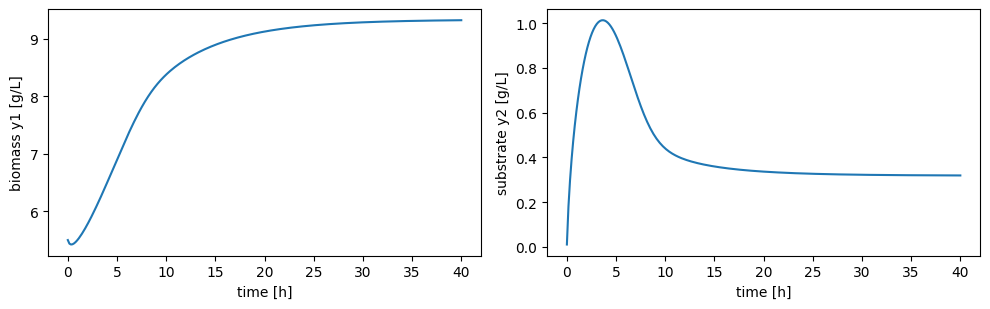

In [3]:
from model import solve_model

t = np.linspace(0, 40, 251)                                       # 0..40 h
out = solve_model(t, [0, 0.01], {'y10': 5.5},                     # y0, tii
                  {'u1': np.full(251, 0.05), 'u2': np.full(251, 30.0)},   # tvi: constant profiles
                  [0.25, 0.25, 0.88, 0.09])                       # theta

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(t, out['tvo']['y1']); ax[0].set(xlabel='time [h]', ylabel='biomass y1 [g/L]')
ax[1].plot(t, out['tvo']['y2']); ax[1].set(xlabel='time [h]', ylabel='substrate y2 [g/L]')
plt.tight_layout(); plt.show()

**What to look for:** smooth curves, no negative concentrations, no explosion. Biomass grows and
levels off. Substrate first rises from the feed and then drops to a low, nearly constant value where
growth is limited. **That low-substrate region is where $K_s$ acts**, so data there will carry most
of the information on $K_s$. If the curves look wrong here, fix the model before going on.

---
## Part 2. The `system` dictionary: the experiment

`system` describes everything about an experiment that is **not** a model parameter: how long it lasts,
what you can change, what you measure and how precisely. Values follow the paper's Case Study 1
(Table 3).

| Key | Meaning | Used by |
|---|---|---|
| `t_s` | `[start, end]` of an experiment, in the model's time unit | all |
| `t_r` | time-grid step for simulation and sampling (smaller = more accurate, slower) | all |
| `t_d` | dead time: no designed sampling or switching this close to the start and end | design |
| `tvi` | **time-variant inputs** $u(t)$, one entry per input (below) | all |
| `tii` | **time-invariant inputs** $w$, one value per experiment: `{'min', 'max'}` | all |
| `tvo` | **time-variant outputs** $y(t)$, one entry per output (below) | all |
| `tio` | time-invariant outputs (e.g. a final yield); empty here | all |
| `errt`, `sigma_floor` | **[MIDDoE extra]** how design reads `unc`: `'abs'` (default) or `'rel'` | design |

Entries of each **`tvi`** input. These matter when MIDDoE *designs* experiments (tutorials 2–3); for
estimation the profiles are read from the data:

| Key | Meaning |
|---|---|
| `min`, `max` | allowed range |
| `cvp` | profile shape: `'CPF'` steps, `'LPF'` linear ramps, `'no_CVP'` constant |
| `stps` | number of levels of the profile |
| `const` | `'rel'` free, `'inc'` only increasing, `'dec'` only decreasing |
| `offl`, `offt` | minimum change between levels, minimum time between switches (absolute units) |

Entries of each **`tvo`** output:

| Key | Meaning | Used by |
|---|---|---|
| `meas` | `True` = measured (used in estimation); `False` = computed but not measured | all |
| `unc` | measurement standard deviation (see Part 4 for absolute vs relative) | data, estimation, design |
| `init` | initial value passed to the model in `y0` (a number, or `'variable'` = take it from `tii['<name>_0']`) | simulation |
| `sp` | number of samples per experiment | data, design |
| `samp_s` | sampling group: outputs with the same number are sampled at the same times | design |
| `samp_f` | sampling times forced into every experiment, e.g. `[0, 40]` | design |
| `offt` | minimum time between two samples | design |

In [4]:
system = {
    # ---------------- time ----------------
    't_s': [0, 40],      # [start, end] of every experiment, in the model's time unit (here h)
    't_r': 0.16,         # step of the time grid used for simulation, inputs and sampling (here h).
                         #   Smaller = more accurate profiles and sampling times, but slower.
                         #   Must match the 'X:all' grid of data.xlsx if you write the file yourself.
    't_d': 0,            # dead time (absolute, same unit as t_s): no designed switching or free
                         #   sampling in the first and last t_d of the run. 0 = no dead time.
                         #   Only used when MIDDoE designs experiments (tutorial 2).
    # 'errt': 'abs',     # how a DESIGN reads 'unc' below: 'abs' (default) = absolute std. dev.,
                         #   'rel' = relative, sigma = max(unc * |y|, sigma_floor). Can also be set per
                         #   output in system['tvo'][y]['errt']. Not used for estimation (that reads
                         #   the MES_E column) nor for in-silico noise (that is insilicos['errt']).
    # 'sigma_floor': 1e-6,  # smallest sigma a design uses with errt='rel' (default 1e-6)

    # ---------------- time-variant inputs u(t): one entry per input ----------------
    # The keys ('u1', 'u2') are the names the model receives in tvi['u1'], tvi['u2'].
    # For ESTIMATION the profiles are read from data.xlsx; the entries below only matter when
    # MIDDoE designs an experiment (tutorial 2), but they must be present.
    'tvi': {
        'u1': {                  # dilution rate [1/h]
            'min': 0.05,         # lowest allowed value (physical units)
            'max': 0.2,          # highest allowed value; an input missing from a preliminary
                                 #   experiment (insilicos['prels']) is set to this value
            'cvp': 'CPF',        # profile shape (control vector parametrisation):
                                 #   'CPF'    = piecewise constant (steps)
                                 #   'LPF'    = piecewise linear (ramps between levels)
                                 #   'no_CVP' = one constant value for the whole run
            'stps': 5,           # number of levels of the profile (stps-1 switching times)
            'const': 'rel',      # shape constraint: 'rel' = free, 'inc' = only increasing,
                                 #   'dec' = only decreasing
            'offl': 0.01,        # minimum change between two consecutive levels (absolute, input units)
            'offt': 0.5,         # minimum time between two switches (absolute, time units)
        },
        'u2': {                  # feed substrate concentration [g/L]
            'min': 5, 'max': 35,
            'cvp': 'LPF',        # ramps (see 'cvp' above)
            'stps': 5, 'const': 'rel', 'offl': 1, 'offt': 0.5,
        },
    },

    # ---------------- time-invariant inputs w: one value per experiment ----------------
    # The keys are the names the model receives in tii[...]. Only 'min' and 'max' are needed.
    'tii': {
        'y10': {'min': 1, 'max': 5.5},   # initial biomass [g/L]; the model reads tii['y10'] itself.
                                         #   (The name '<output>_0', e.g. 'y1_0', is only needed
                                         #   with system['tvo'][y]['init'] = 'variable', below.)
    },

    # ---------------- time-variant outputs y(t): one entry per output ----------------
    # The keys ('y1', 'y2') must be the keys the model returns in {'tvo': {...}}.
    'tvo': {
        'y1': {                  # biomass [g/L]
            'meas': True,        # True = measured, used in estimation and design;
                                 #   False = computed by the model but not measured (ignored by the fit)
            'unc': 0.08,         # measurement standard deviation. Absolute (g/L) or relative (8 %),
                                 #   depending on insilicos['errt'] (data) / system['errt'] (design).
                                 #   Estimation uses the MES_E column of data.xlsx; 'unc' is the
                                 #   fallback (absolute) where MES_E is missing.
            'init': 0,           # initial value passed to the model in y0: a number, or 'variable'
                                 #   = take it from system['tii']['y1_0'] (one value per experiment).
                                 #   This model ignores y0 and builds y1(0) from tii['y10'].
            'sp': 10,            # number of samples per experiment (including forced ones in samp_f)
            'samp_s': 1,         # sampling group (integer): outputs with the same number are sampled
                                 #   at the same times; different numbers = independent schedules
            'samp_f': [],        # sampling times forced into every designed experiment, e.g. [0, 40];
                                 #   [] = none
            'offt': 0.5,         # minimum time between two samples (absolute, time units)
        },
        'y2': {                  # substrate [g/L]; same keys and meanings as y1
            'meas': True, 'unc': 0.08, 'init': 0.01, 'sp': 10, 'samp_s': 1, 'samp_f': [], 'offt': 0.5,
        },
    },

    # ---------------- time-invariant outputs ----------------
    'tio': {},           # outputs with one value per experiment (e.g. a final yield), same entries
                         #   as 'tvo'; returned by the model in {'tio': {...}}. Empty here.
}

---
## Part 3. The `models` dictionary: the model and its parameters

Every entry is a dict keyed by the model name (`'MI'`), so several rival models can be listed side by
side for model discrimination.

| Key | Meaning |
|---|---|
| `can_m` | list of the candidate models to use |
| `krt` | how to run the model: `'pys'` = Python file with `solve_model` (also `'pym'`, a function, `'gpr'`) |
| `src` | path of the model file (for `'pys'`/`'gpr'`); relative to the working folder, or absolute |
| `creds` | gPROMS licence credentials; `''` otherwise |
| `theta` | starting guess of the parameters (physical units). Estimation starts here, and **fixed parameters keep this value** |
| `t_l`, `t_u` | lower and upper bounds of each parameter, absolute values (physical units) |
| `mutation` | `True` = estimate this parameter, `False` = keep it fixed at its `theta` value |

As in the paper, the starting guess is 20 % above the true values and the bounds are ±50 % around them.
Estimation works on the scaled parameters $\theta/\theta_{start}$, so a parameter must not start at 0.

MIDDoE also **writes into `models`**: after `uncert()` it stores the new estimates (`theta`,
`thetastart`), their covariance (`V_matrix`) and sensitivities (`LSA`). That is how the next
experiment design (tutorial 2) uses the latest estimates.

In [5]:
theta_true = [0.25, 0.25, 0.88, 0.09]      # used only by the virtual lab (Part 4)

# Every entry except 'can_m' is a dict keyed by the model name, so several rival models can be
# listed side by side (model discrimination, tutorial 3). Here there is one model, 'MI'.
models = {
    'can_m': ['MI'],          # candidate models to use, e.g. ['MI', 'MII', 'MIII'] for discrimination.
                              #   Every name needs an entry in each dict below.

    'krt': {'MI': 'pys'},     # how MIDDoE runs the model:
                              #   'pys' = a Python file (path in 'src') defining
                              #           solve_model(t, y0, tii, tvi, theta)   <- used here
                              #   'pym' = a built-in model: the model name must be a function of
                              #           middoe.krnl_models (for tests and examples)
                              #   'gpr' = a gPROMS model (gPAS file in 'src', licence in 'creds';
                              #           needs pygpas)
                              #   a function object f(t, y, phi, phit, theta, te) returning dy/dt
                              #           (not a string); MIDDoE integrates it and names the
                              #           outputs y1..yN in state order

    'src': {'MI': str(HERE / 'model.py')},   # model file for 'pys'/'gpr': absolute path, or
                              #   relative to the working folder. Ignored for 'pym' and functions.

    'creds': {'MI': ''},      # gPROMS credentials 'user:password@server' for 'gpr'; '' otherwise

    'theta': {'MI': [0.30, 0.30, 1.056, 0.108]},   # starting guess (physical units, model order:
                              #   mu_max, Ks, Yxs, m). Here 1.2 x true. Must not be 0 (estimation
                              #   works on theta / theta_start). Fixed parameters keep this value.
                              #   uncert() overwrites it with the latest estimate.

    't_l': {'MI': [0.125, 0.125, 0.44, 0.045]},    # lower bounds (absolute, physical units); 0.5 x true
    't_u': {'MI': [0.375, 0.375, 1.32, 0.135]},    # upper bounds (absolute, physical units); 1.5 x true
                              #   Bounds that exclude 0 let the optimiser work in log scale
                              #   (iden_opt['pscale'] = 'log', the default).

    'mutation': {'MI': [True, True, True, True]},  # per parameter: True = estimate it,
                              #   False = keep it fixed at its 'theta' value (e.g. a parameter the
                              #   estimability analysis finds poorly determined). Here all four free.

    # Written by MIDDoE later (do not set them yourself):
    #   'thetastart' - the first starting guess, used by parmest(..., case='strov')
    #   'V_matrix'   - covariance of the estimates, from uncert()
    #   'LSA'        - sensitivities of the measured points, from uncert()
}

---
## Part 4. In-silico data and measurement errors

Before running real experiments it is good practice to test the whole study on **synthetic data**: a
"virtual lab" simulates the experiment with known *true* parameters and adds random measurement noise.
You can then check that MIDDoE recovers the true values. The virtual lab is set in `insilicos`:

| Key | Meaning |
|---|---|
| `tr_m` | the model that plays the real process (a name in `can_m`) |
| `theta` | its true parameter values |
| `errt` | noise type: `'abs'` or `'rel'` (below) |
| `sigma_floor` | **[MIDDoE extra]** smallest σ allowed with `'rel'` (default `1e-6`) |
| `prels` | simple "preliminary" experiments, keyed by experiment number: `{'1': {'u1': 0.05, 'u2': 30, 'y10': 5.5}, ...}`. Inputs held constant; an input left out is set to its `max` |

**The two error types.** `unc` of each output (Part 2) is turned into a standard deviation σ for every
measurement:

| `errt` | σ of a measurement | Typical for | Consequence |
|---|---|---|---|
| `'abs'` | σ = `unc` (same for every point) | balances, gauges with a fixed precision | small values are relatively very noisy |
| `'rel'` | σ = max(`unc` × \|true value\|, `sigma_floor`) | analysers with a % precision | small values are measured very precisely, so they get a **large weight** in the fit |

The noisy value is drawn from a normal distribution around the true value. **[MIDDoE extra]** Negative
draws are set to 0 (concentrations cannot be negative), and the σ used is written next to every value
in the data file (`MES_E` columns, Part 5).

Here we use `'rel'` with `unc = 0.08` (8 % noise), as in the paper-era runner of Case Study 1. Part 8 repeats the whole study with other error types
and noise levels and compares the results.

**Running an experiment.** `expera(system, models, insilicos, design_decisions, expr)` simulates
experiment number `expr` and adds it to `data.xlsx` as sheet `'expr'`. With
`design_decisions = {}` it runs `insilicos['prels'][str(expr)]`; in tutorial 2 we pass a designed
experiment instead.

[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


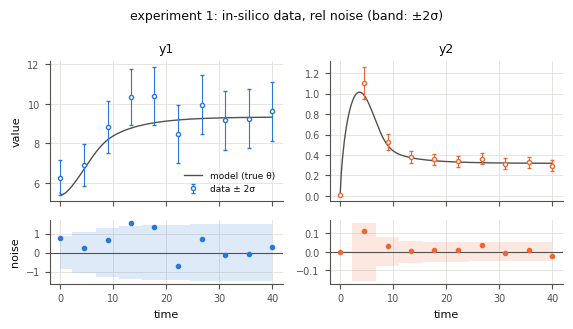

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\data_plots\experiment_1.png


[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


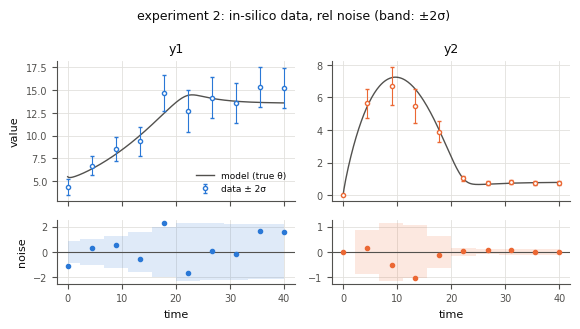

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\data_plots\experiment_2.png


[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


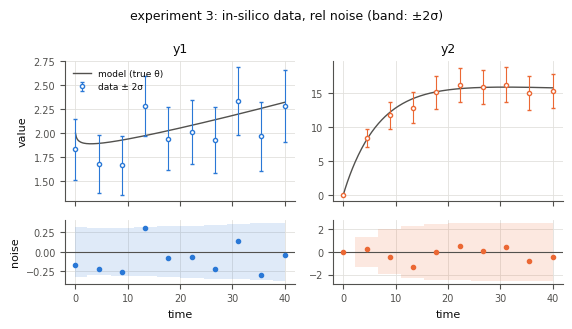

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\data_plots\experiment_3.png


In [6]:
insilicos = {
    'tr_m': 'MI',            # the model that plays the "real" process: a name in models['can_m'].
                             #   In a discrimination study it can differ from the model you fit.
    'theta': theta_true,     # its true parameter values (physical units, model order)
    'errt': 'rel',           # noise added to the synthetic data:
                             #   'abs' = absolute: sigma = unc (same for every point)
                             #   'rel' = relative: sigma = max(unc * |true value|, sigma_floor)
                             #   (unc is system['tvo'][y]['unc'])
    # 'sigma_floor': 1e-6,   # smallest sigma with 'rel' (default 1e-6), so a true value of 0
                             #   never gives sigma = 0. Set it to the detection limit (Part 8).
    'prels': {               # preliminary ("classic") experiments, keyed by experiment number.
                             #   Each input is held constant; an input left out is set to its 'max'.
                             #   Required, even if you only run designed experiments.
        '1': {'u1': 0.05, 'u2': 30, 'y10': 5.5},
        '2': {'u1': 0.10, 'u2': 30, 'y10': 5.5},
        '3': {'u1': 0.15, 'u2': 20, 'y10': 2.0},
    },
}

for experiment in [1, 2, 3]:
    # expera(system, models, insilicos, design_decisions, expr, swps=None)
    #   design_decisions: {} = run insilicos['prels'][str(expr)]; a design returned by
    #                     mbdoe_pp/mbdoe_md = run that designed experiment (tutorial 2)
    #   expr:             experiment number = sheet name in data.xlsx (a rerun replaces the sheet)
    #   swps:             switching times/levels of a design (with design_decisions); None here
    expera(system, models, insilicos, {}, expr=experiment)

**Absolute vs relative errors, side by side.** We generate experiment 1 once more with `'abs'`
errors, in a separate folder so that our `data.xlsx` stays unchanged, and compare the σ of the
substrate measurements:

[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\abs_demo\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


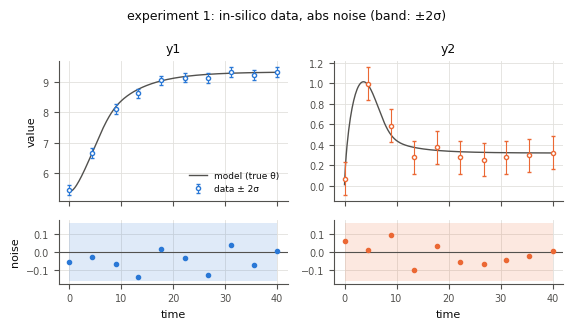

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\abs_demo\data_plots\experiment_1.png
[INFO] Reading from data.xlsx
[INFO] Reading from data.xlsx


,time [h],substrate y2,"sigma, rel 8 %","sigma, abs 0.08"
0,0.00,0.010115,0.000800,0.08
1,4.48,1.100059,0.078833,0.08
2,8.96,0.523690,0.039491,0.08
3,13.28,0.377833,0.029935,0.08
4,17.76,0.356207,0.027519,0.08
5,22.24,0.339718,0.026471,0.08


In [7]:
(HERE / 'abs_demo').mkdir(exist_ok=True)
os.chdir(HERE / 'abs_demo')
expera(system, models, dict(insilicos, errt='abs'), {}, expr=1)
data_abs = read_excel()
os.chdir(HERE)

data = read_excel()                       # the 'rel' data we keep
pd.DataFrame({'time [h]':        data['1']['MES_X:y2'],
              'substrate y2':    data['1']['MES_Y:y2'],
              'sigma, rel 8 %':  data['1']['MES_E:y2'],
              'sigma, abs 0.08': data_abs['1']['MES_E:y2']}).head(6)

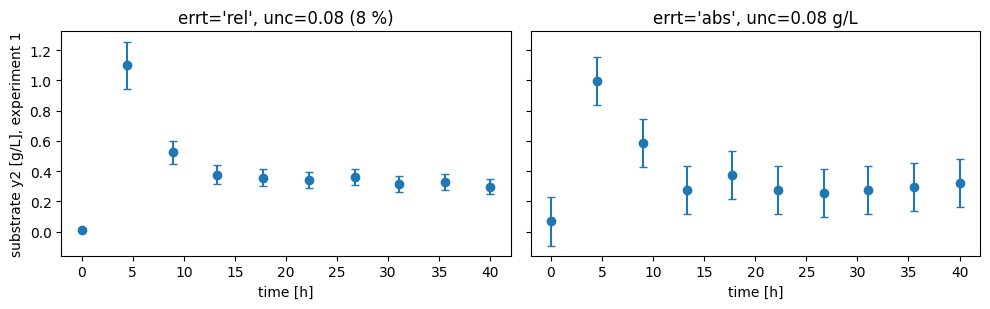

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for a, d, title in [(ax[0], data['1'], "errt='rel', unc=0.08 (8 %)"), (ax[1], data_abs['1'], "errt='abs', unc=0.08 g/L")]:
    a.errorbar(d['MES_X:y2'], d['MES_Y:y2'], yerr=2 * d['MES_E:y2'], fmt='o', capsize=3)   # bars = +/- 2 sigma
    a.set(title=title, xlabel='time [h]')
ax[0].set_ylabel('substrate y2 [g/L], experiment 1')
plt.tight_layout(); plt.show()

Look at the first row ($t = 0$, $y_2 = 0.01$ g/L):

- With `'rel'`, σ = 0.08 × 0.01 = 0.0008 g/L. In a weighted fit this single point gets a weight
  $1/σ^2 \approx 1.6\times10^{6}$, far more than any other point. The fit will match it almost exactly.
- With `'abs'`, σ = 0.08 g/L everywhere. Now the point is 8 times noisier than its own value.

Neither is "right": choose the type that matches your instrument. If relative errors make values near
zero dominate, raise `sigma_floor` (e.g. `insilicos['sigma_floor'] = 0.01`) so σ never drops below a
realistic detection limit.

---
## Part 5. The data file `data.xlsx`

MIDDoE reads all measurements from **`data.xlsx` in the working folder**. **Each sheet is one
experiment.** For real experiments you fill in this file yourself, with the same columns:

| Column(s) | Content |
|---|---|
| `MES_X:y1`, `MES_Y:y1`, `MES_E:y1` | sampling times, measured values and their σ (absolute) for output `y1`; the same triple for every measured output |
| `X:all` | the full time grid (step `t_r`) on which the input profiles are listed |
| `y10` | each `tii` input; only the first row is read |
| `u1`, `u2` | each `tvi` input profile, listed on `X:all` |
| `CVP:u1`, `CVP:u2` | profile type: `'no_CVP'` (constant, as here), `'CPF'` or `'LPF'`. Designed experiments also have `u1t`/`u1l` columns (switching times and levels) |

Notes:

- The sampling times of each output may differ, and each output may have a different number of samples.
- If `MES_E` is missing, `system['tvo'][y]['unc']` is used as σ.
- `read_excel()` returns the whole file as a dict `{sheet name: table}`. **[MIDDoE extra]** That dict
  can be passed to `parmest`/`uncert` with `data=...`, e.g. to fit a subset of the experiments
  (Part 7).

In [9]:
print('experiments (sheets):', list(data))
data['1'].head(8)

experiments (sheets): ['1', '2', '3']


,MES_X:y1,MES_Y:y1,MES_E:y1,MES_X:y2,MES_Y:y2,MES_E:y2,X:all,y10,u1,u2,CVP:u1,CVP:u2
0,0.00,6.276183,0.440000,0.00,0.010115,0.000800,0.00,5.5,0.05,30,no_CVP,no_CVP
1,4.48,6.902789,0.535093,4.48,1.100059,0.078833,0.16,5.5,0.05,30,NaN,NaN
2,8.96,8.820927,0.654433,8.96,0.523690,0.039491,0.32,5.5,0.05,30,NaN,NaN
3,13.28,10.330507,0.700806,13.28,0.377833,0.029935,0.48,5.5,0.05,30,NaN,NaN
4,17.76,10.388703,0.723067,17.76,0.356207,0.027519,0.64,5.5,0.05,30,NaN,NaN
5,22.24,8.461543,0.734335,22.24,0.339718,0.026471,0.80,5.5,0.05,30,NaN,NaN
6,26.72,9.954628,0.740116,26.72,0.363397,0.025968,0.96,5.5,0.05,30,NaN,NaN
7,31.04,9.175290,0.743020,31.04,0.316265,0.025723,1.12,5.5,0.05,30,NaN,NaN


### Looking at the data

Always plot the data before fitting. The two small helpers below are used for the rest of the
notebook:

- `simulate(sheet, theta)` runs `model.py` with the inputs stored in one sheet. This is what MIDDoE
  does internally.
- `plot_fit(curves)` draws the data of all experiments (points with ±2σ bars, σ = `MES_E`) and one model curve per
  parameter set, so that different fits can be compared by eye.

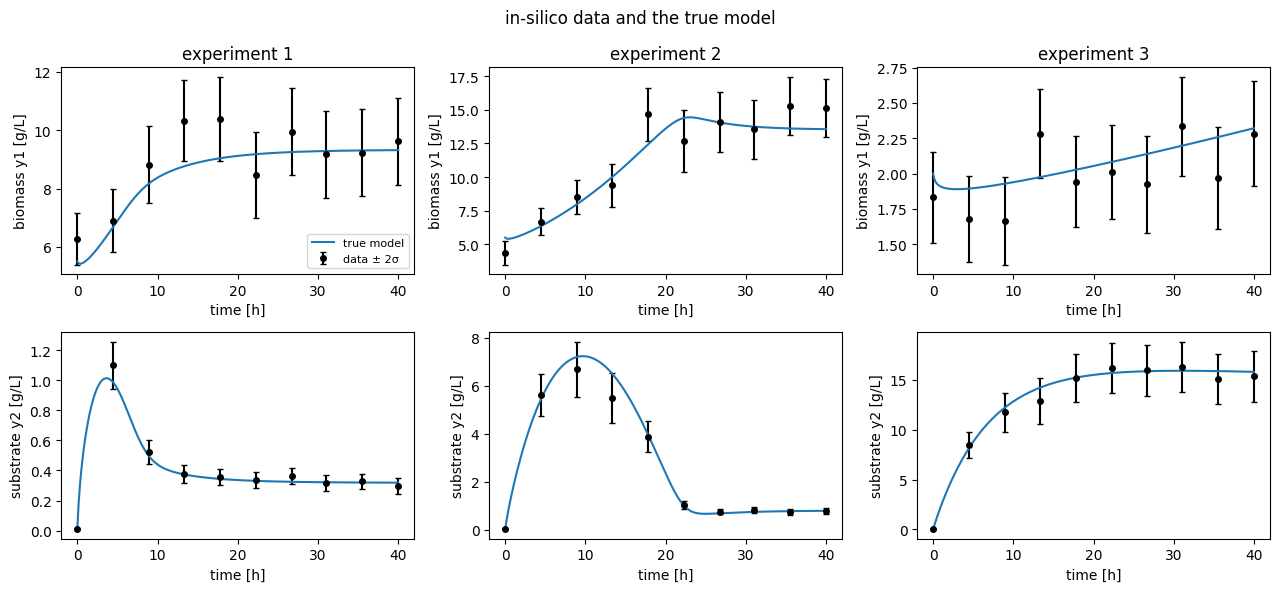

In [10]:
def simulate(sheet, theta):
    t = sheet['X:all'].dropna().values                          # time grid of this experiment
    n = len(t)
    out = solve_model(t, [0, 0.01], {'y10': sheet['y10'].iloc[0]},
                      {'u1': sheet['u1'].values[:n], 'u2': sheet['u2'].values[:n]}, list(theta))
    return t, out['tvo']


def plot_fit(curves, dataset=None, title=''):
    dataset = data if dataset is None else dataset
    fig, ax = plt.subplots(2, len(dataset), figsize=(4.3 * len(dataset), 6), squeeze=False)
    for j, (name, sheet) in enumerate(dataset.items()):
        for i, y in enumerate(['y1', 'y2']):
            ax[i, j].errorbar(sheet[f'MES_X:{y}'], sheet[f'MES_Y:{y}'], yerr=2 * sheet[f'MES_E:{y}'],
                              fmt='o', color='k', ms=4, capsize=2, label='data ± 2σ')
            for k, (label, theta) in enumerate(curves.items()):
                t, out = simulate(sheet, theta)
                ax[i, j].plot(t, out[y], ls=['-', '--', ':', '-.'][k % 4], label=label)   # styles keep overlapping curves visible
            ax[i, j].set(xlabel='time [h]', ylabel=f"{['biomass', 'substrate'][i]} {y} [g/L]")
        ax[0, j].set_title(f'experiment {name}')
    ax[0, 0].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout(); plt.show()


plot_fit({'true model': theta_true}, title='in-silico data and the true model')

**What to look for:**

- **How to read the bars.** Each bar is ±2σ, with σ the declared standard deviation in `MES_E`. If
  the noise is as declared, about 95 % of the bars cross the true curve and about 1 in 20 misses it.
  Here 3 of the 60 points miss: biomass at 13 h in experiment 1, and at 0 h and 18 h in experiment 2.
  (With ±1σ bars, one point in three would miss the curve; that is normal, not a bad fit.)
- σ is computed from the *true* value (σ = 8 % of the noise-free value), not from the measured one.
  A point that came out high therefore has a bar that looks short for its height, and one that came
  out low a bar that looks long.
- The first biomass point is a measurement too: it scatters around $y_{10}$, while the model starts
  exactly at $y_{10}$.
- Check the axis scale: the biomass axis of experiment 3 spans only about 1.4–2.7 g/L, so 8 % noise looks
  large there.
- The three experiments cover different conditions: dilution rate 0.05, 0.10 and 0.15 1/h, and a
  lower starting biomass in experiment 3. Different conditions are what make parameters separable.
- The substrate bars are tiny at low values (relative errors), so those points will dominate a
  weighted fit.
- With real data, look also for outliers, missing values and sampling times outside the experiment.
  Fix the file before fitting.

---
## Part 6. Parameter estimation: `parmest`

`parmest(system, models, iden_opt)` finds the parameter values that make the model reproduce the data
best. For each model in `can_m` it minimises an **objective** over the free parameters (those with
`mutation = True`), within the bounds, starting from `models['theta']`. Internally the parameters are
scaled, $x = \theta / \theta_{start}$, so all of them are of order 1 for the optimiser.

All options are in the `iden_opt` dictionary:

| Key | Options | Meaning and consequences |
|---|---|---|
| `meth` | `'SLSQP'`, `'LMBFGS'`, `'TC'`, `'NMS'`, `'BFGS'`, `'DE'` | the optimiser (Part 6.1) |
| `ob` | `'WLS'`, `'LS'`, `'MLE'`, `'Chi'` | the objective (Part 6.3) |
| `ms` | `True` / `False` | multi-start: repeat the fit from several random points inside the bounds, in parallel, and keep the best. Protects against local minima |
| `maxit` | e.g. `500` | maximum optimiser iterations (generations for `'DE'`) |
| `tol` | e.g. `1e-8` | convergence tolerance, relative to the objective at the optimum. A loose value stops early, possibly still reporting success: estimates are then off and the Hessian covariance (Part 7) can fail (Part 6.2). Use 1e-6 to 1e-9 |
| `pscale`, `grad`, `grad_step`, `fnorm` | defaults `'log'`, `'2-point'`, `1e-6`, `True` | **[MIDDoE extra]** optimiser numerics (Part 6.1); keep the defaults. `pscale='lin'`, `grad='legacy'`, `fnorm=False` give the behaviour of older versions |
| `var-cov` | `'M'`, `'H'`, `'B'` | covariance method (Part 7). **Set it before `parmest`**: `'H'` and `'B'` are computed during the estimation |
| `nboot` | e.g. `100` | number of bootstrap repetitions (only with `'B'`) |
| `sens_m`, `eps` | `'central'`/`'forward'`, e.g. `1e-3` or `None` | finite differences for the sensitivities (Part 7.3) |
| `log` | `True` / `False` | print every trial point |
| `c_plt`, `f_plt`, `plt_s` | `True` / `False` | confidence-region plots, fit plots, and whether to show them on screen; made by `save_rounds` (Part 9) |

The paper's supplementary Table S3 uses older option names. They still work and are mapped
automatically: `'G'` → `'DE'`, `'Ls'` → `'SLSQP'`, `'Ln'`/`'NM'` → `'NMS'`, `'SQP'` → `'TC'`,
`'LBFGSB'` → `'LMBFGS'`, `'CS'` → `'Chi'`, `'J'` → `'M'`. Any other unknown value is an error.

Other arguments of `parmest`:

- `case`: `None` (default) starts from `models['theta']`. `'strov'` starts from `models['thetastart']`,
  the first estimate ever stored, which is useful in sequential rounds. Neither changes `mutation`.
- **[MIDDoE extra]** `data`: a dict from `read_excel()` to use instead of `data.xlsx`.

The reference settings of this notebook: SLSQP, weighted least squares, Fisher covariance.

In [11]:
iden_opt = {
    # ---------------- estimation (parmest) ----------------
    'meth': 'SLSQP',     # optimiser (required), see Part 6.1:
                         #   'SLSQP'  local, gradient-based, bounded            <- used here
                         #   'LMBFGS' local, L-BFGS-B quasi-Newton, bounded (good for many parameters)
                         #   'TC'     local, trust-region constrained (robust, slower)
                         #   'NMS'    local, Nelder-Mead simplex, derivative-free
                         #   'BFGS'   local quasi-Newton, ignores the bounds
                         #   'DE'     global, differential evolution (slow, start-independent)
                         #   paper names also work: 'Ls', 'LBFGSB', 'SQP', 'Ln'/'NM', 'G'
    'ob': 'WLS',         # objective (required), see Part 6.3:
                         #   'WLS' weighted least squares, sum((r/sigma)^2)    <- used here
                         #   'MLE' Gaussian maximum likelihood (same estimates as WLS with known sigma)
                         #   'LS'  plain least squares, ignores sigma
                         #   'Chi' relative least squares, for relative errors (paper name 'CS')
    'ms': False,         # multi-start: True = also fit from random starts inside the bounds, in
                         #   parallel, and keep the best (protects against local minima). Default False.
    'maxit': 500,        # maximum iterations (generations for 'DE'). Default 1000.
    'tol': 1e-8,         # stopping tolerance, relative to the objective. Default 1e-6.
                         #   Use 1e-6 ... 1e-9; a loose value (1e-1) stops early but still reports
                         #   success (Part 6.2).
    # Advanced optimiser numerics (MIDDoE extra, keep the defaults):
    # 'pscale': 'log',     # 'log' = optimise log(theta/theta0) where the bounds exclude 0; 'lin' = theta/theta0
    # 'grad': '2-point',   # finite-difference gradient: '2-point', '3-point' (central, 2x cost), 'legacy'
    # 'grad_step': 1e-6,   # relative step of that gradient
    # 'fnorm': True,       # normalise the objective so 'tol' is relative for every method; False = off

    # ---------------- uncertainty (set BEFORE parmest: 'H' and 'B' are computed there) ----------------
    'var-cov': 'M',      # covariance method, see Part 7.1:
                         #   'M' Fisher information from the sensitivities (fast, linearised) <- used here
                         #       (paper name 'J')
                         #   'H' inverse Hessian of the objective (fast; default if the key is missing)
                         #   'B' bootstrap: refit nboot resampled data sets (slow, no linearisation)
    'nboot': 10,         # bootstrap repetitions, only with 'B' (default 100; the paper uses 500)
    # 'boot_start': 'mixed',  # start of each bootstrap refit (only with 'B'): 'mixed' (default) =
                         #   from the estimate, plus 4 random starts when ms=True; 'ref' = from the
                         #   estimate only (fastest); 'multi' = like the main fit (slowest)
    'sens_m': 'central', # finite differences for the sensitivities: 'central' (default, accurate)
                         #   or 'forward' (half the model runs, less accurate), see Part 7.3
    'eps': 1e-3,         # relative step of those differences, e.g. 1e-3 ... 1e-5; None (default) =
                         #   search for a step where the sensitivities are stable (extra model runs)

    # ---------------- output ----------------
    'log': False,        # True = print every trial point of the optimiser (very long output)
    'c_plt': True,       # save_rounds(): draw the confidence ellipses -> folder confidence/
    'f_plt': True,       # save_rounds(): draw data vs fitted model     -> folder modelling/
    'plt_s': False,      # save_rounds(): also show those plots on screen (False = only save them)
}
models_start = copy.deepcopy(models)          # keep the starting guess: uncert() later overwrites models['theta']

# parmest(system, models, iden_opt, case=None, data=None)
#   case: None    = start from models['theta']
#         'strov' = start from models['thetastart'] (the first guess ever stored; sequential rounds)
#   data: None    = read data.xlsx from the working folder; or a dict from read_excel() (Part 7.4)
resultpr = parmest(system, models, iden_opt)

fit = resultpr['MI']
print('converged:', fit['success'], '|', fit['message'])
print('objective value:', round(fit['fun'], 3), '| model runs:', fit['nfev'])
pd.DataFrame({'start': models['theta']['MI'], 'estimate': fit['scpr'], 'true': theta_true}, index=NAMES)

[INFO] Reading from data.xlsx


converged: True | Optimization terminated successfully
objective value: 60.709 | model runs: 134


,start,estimate,true
mu_max,0.300,0.228549,0.25
Ks,0.300,0.292463,0.25
Yxs,1.056,0.788307,0.88
m,0.108,0.068070,0.09


**Look at the fit.** The starting guess, the fitted model and the true model against the data:

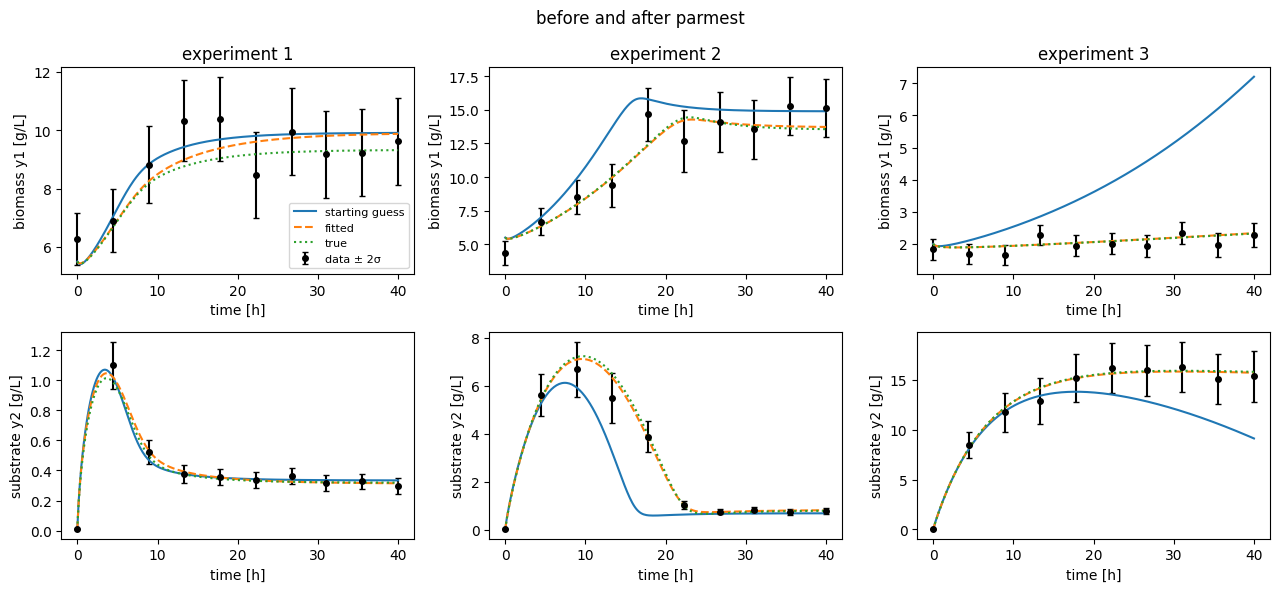

In [12]:
plot_fit({'starting guess': models_start['theta']['MI'], 'fitted': fit['scpr'], 'true': theta_true},
         title='before and after parmest')

**Check the residuals.** A residual is data minus model at a sampling time. Dividing it by the
σ of the point gives a *weighted residual*. If the model is right and σ is right, the weighted residuals
look like random numbers with mean 0 and standard deviation 1: about 95 % within ±2, and no trend
with time.

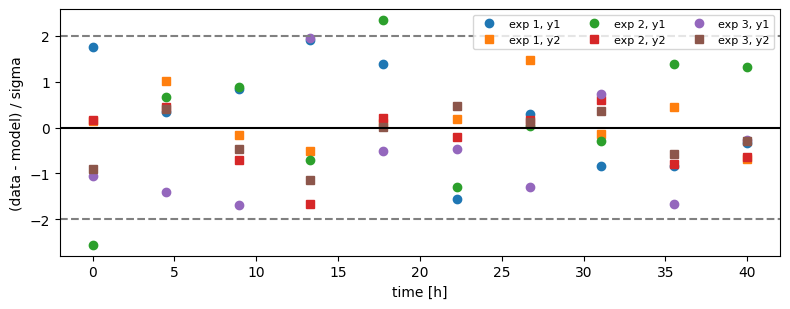

WLS / (N - number of parameters) = 60.7 / (60 - 4) = 1.08   (about 1 expected)


In [13]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for name, sheet in data.items():
    t, out = simulate(sheet, fit['scpr'])
    for y, marker in [('y1', 'o'), ('y2', 's')]:
        model_at_samples = np.interp(sheet[f'MES_X:{y}'], t, out[y])
        weighted = (sheet[f'MES_Y:{y}'] - model_at_samples) / sheet[f'MES_E:{y}']
        ax.plot(sheet[f'MES_X:{y}'], weighted, marker, label=f'exp {name}, {y}')
for level in (-2, 2):
    ax.axhline(level, ls='--', color='gray')
ax.axhline(0, color='k'); ax.set(xlabel='time [h]', ylabel='(data - model) / sigma')
ax.legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()

N = sum(sheet['MES_Y:y1'].notna().sum() + sheet['MES_Y:y2'].notna().sum() for sheet in data.values())
print(f'WLS / (N - number of parameters) = {fit["fun"]:.1f} / ({N} - 4) = {fit["fun"] / (N - 4):.2f}   (about 1 expected)')

**What to look for:**

- Points scattered evenly around 0, mostly between the dashed lines: the fit is good.
- A **trend** (e.g. all positive at the start, all negative at the end) would mean the model misses
  something, a *model* problem.
- **WLS/(N − p) ≈ 1** means the scatter matches the declared σ. Much larger means σ is too small or
  the model is wrong; much smaller means σ is too large. Part 8.4 uses this check.

`resultpr['MI']` holds the optimiser's report:

- `scpr`: the estimates in physical units;
- `fun`: the objective value at the estimates;
- `success` and `message`: whether and why it stopped;
- `nfev`: the number of model runs;
- `activeparams`: which parameters were free.

The estimates are close to, but not exactly, the true values, because the data are noisy. Part 7
tells us how close we can expect them to be.

### 6.1 Optimisation routes

| `meth` | Type | Uses bounds | Cost | When to use |
|---|---|---|---|---|
| `'SLSQP'` | local, gradient-based (sequential quadratic programming) | yes | low | default; smooth problems with a reasonable start |
| `'LMBFGS'` | local, gradient-based (L-BFGS-B quasi-Newton) | yes | low | many parameters; the paper's Case Study 2 |
| `'TC'` | local, gradient-based trust region (SciPy *trust-constr*) | yes | medium | the paper's Case Study 1 (old key `'SQP'`); robust but slow |
| `'NMS'` | local, derivative-free simplex (Nelder–Mead) | yes | medium | noisy or non-smooth objectives |
| `'BFGS'` | local, gradient-based quasi-Newton | **no** (but see below) | low | unbounded problems. It ignores the bounds; MIDDoE's log variables keep a positive parameter positive, but it can still go beyond the bounds |
| `'DE'` | **global**, population-based (differential evolution) | yes (searches only inside them) | very high | many local minima, or no idea of a starting point |
| any + `ms=True` | several local fits from random starts in parallel | as the method | starts × one fit (but parallel) | protection against local minima at moderate cost |

Gradient-based methods compute the gradient by finite differences, so each iteration costs one model
run per free parameter. **[MIDDoE extra]** Three things make every method behave the same
whatever the units of the parameters and the size of the objective:

- **Relative parameter steps.** The optimiser works on $\log(\theta/\theta_0)$ (for parameters whose
  bounds exclude 0), so a step means the same *relative* change for $\mu_{max} \approx 0.5$ as for a
  parameter of $10^5$, however far the optimum is from the start.
- **A gradient that is not noise.** Forward differences with a relative step of $10^{-6}$. SciPy's
  default (an absolute step of $10^{-8}$) is mostly rounding noise for parameters to which the fit
  is weakly sensitive.
- **A normalised objective.** The objective is divided by its own size (and restarted once it has
  fallen 10 times), so `tol` means a *relative* change of the objective for every method. MLE is
  minimised without its constant (same minimum).

`iden_opt` keys `pscale='lin'`, `grad='legacy'`, `fnorm=False` switch these off (older behaviour).

We run every method from the same starting guess. If a method fails, MIDDoE stops with a clear error
instead of returning nonsense; the code catches that error to keep going.

In [14]:
routes = {}
for method in ['SLSQP', 'LMBFGS', 'TC', 'NMS', 'BFGS', 'DE']:
    start = time.time()
    try:
        fit_m = parmest(system, copy.deepcopy(models_start), dict(iden_opt, meth=method))['MI']
        routes[method] = [round(fit_m['fun'], 3), fit_m['nfev'], round(time.time() - start)] + list(np.round(fit_m['scpr'], 4))
    except RuntimeError as error:
        print(f'{method} FAILED: {str(error)[:160]}')

start = time.time()
fit_ms = parmest(system, copy.deepcopy(models_start), dict(iden_opt, ms=True))['MI']
routes['SLSQP + ms'] = [round(fit_ms['fun'], 3), fit_ms['nfev'], round(time.time() - start)] + list(np.round(fit_ms['scpr'], 4))

routes_table = pd.DataFrame(routes, index=['objective', 'model runs', 'time [s]'] + NAMES).T
routes_table

[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx


.venv\Lib\site-packages\scipy\optimize\_differentiable_functions.py:231: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)


[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx


,objective,model runs,time [s],mu_max,Ks,Yxs,m
SLSQP,60.709,134.0,97.0,0.2285,0.2925,0.7883,0.0681
LMBFGS,60.709,195.0,137.0,0.2285,0.2925,0.7883,0.0681
TC,60.709,1960.0,211.0,0.2285,0.2925,0.7883,0.0681
NMS,60.709,422.0,39.0,0.2285,0.2925,0.7882,0.0680
BFGS,60.709,452.0,42.0,0.2285,0.2925,0.7883,0.0681
DE,60.709,14040.0,685.0,0.2285,0.2925,0.7882,0.0680
SLSQP + ms,60.709,207.0,23.0,0.2285,0.2925,0.7882,0.0680


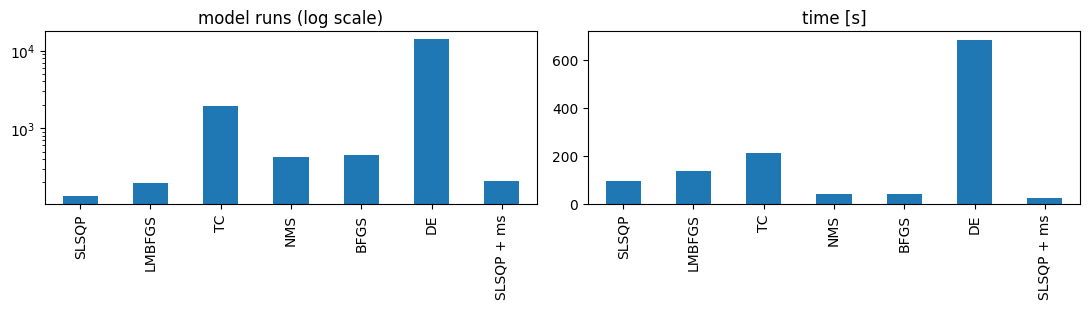

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
routes_table['model runs'].plot.bar(ax=ax[0], logy=True, title='model runs (log scale)')
routes_table['time [s]'].plot.bar(ax=ax[1], title='time [s]')
plt.tight_layout(); plt.show()

How to read the table:

- **All methods that finish reach the same objective and the same estimates.** The problem has one
  clear minimum. If methods disagree, the objective has several local minima: use `ms=True` or `'DE'`
  and keep the best.
- **The cost differs a lot.** SLSQP needs the fewest model runs. NMS needs no gradients but more runs.
  TC is careful and slow. DE evaluates a whole population every generation: by far the most model runs,
  but it does not depend on the starting guess.
- **BFGS works here, though it ignores the bounds.** The optimiser moves in $\log(\theta/\theta_0)$
  (Part 6.1), so it cannot make a positive parameter negative, which would stop the ODE solver. (With
  `pscale='lin'`, the older behaviour, BFGS tries a negative parameter and fails.) It can still
  leave the bounds, so prefer a bounded method.
- For `ms=True`, `model runs` counts only the best start; the time includes all starts, run in
  parallel.

### 6.2 Optimiser settings: when can you trust "converged"?

`tol` and `maxit` decide when the optimiser stops. For the gradient methods `tol` is the relative
decrease of the objective below which an iteration counts as "no progress". We loosen them on purpose
and compare with the reference fit (objective 60.7):

In [16]:
settings = {'reference (tol 1e-8)': dict(iden_opt),
            'tol = 1e-2':          dict(iden_opt, tol=1e-2),
            'tol = 1e-1':          dict(iden_opt, tol=1e-1),
            'maxit = 3':           dict(iden_opt, maxit=3)}
stopped, curves = {}, {}
for label, opt in settings.items():
    fit_s = parmest(system, copy.deepcopy(models_start), opt)['MI']
    stopped[label] = [fit_s['success'], fit_s['message'][:40], round(fit_s['fun'], 1), fit_s['nfev']] + list(np.round(fit_s['scpr'], 4))
    curves[label] = fit_s['scpr']
pd.DataFrame(stopped, index=['success', 'message', 'objective', 'model runs'] + NAMES).T

[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx


,success,message,objective,model runs,mu_max,Ks,Yxs,m
reference (tol 1e-8),True,Optimization terminated successfully,60.7,134,0.2285,0.2925,0.7883,0.0681
tol = 1e-2,True,Optimization terminated successfully,77.8,32,0.2589,0.2405,0.9137,0.0999
tol = 1e-1,True,Optimization terminated successfully,394.7,7,0.2749,0.3068,1.0397,0.1104
maxit = 3,False,Iteration limit reached,76.2,36,0.2614,0.2505,0.9204,0.0996


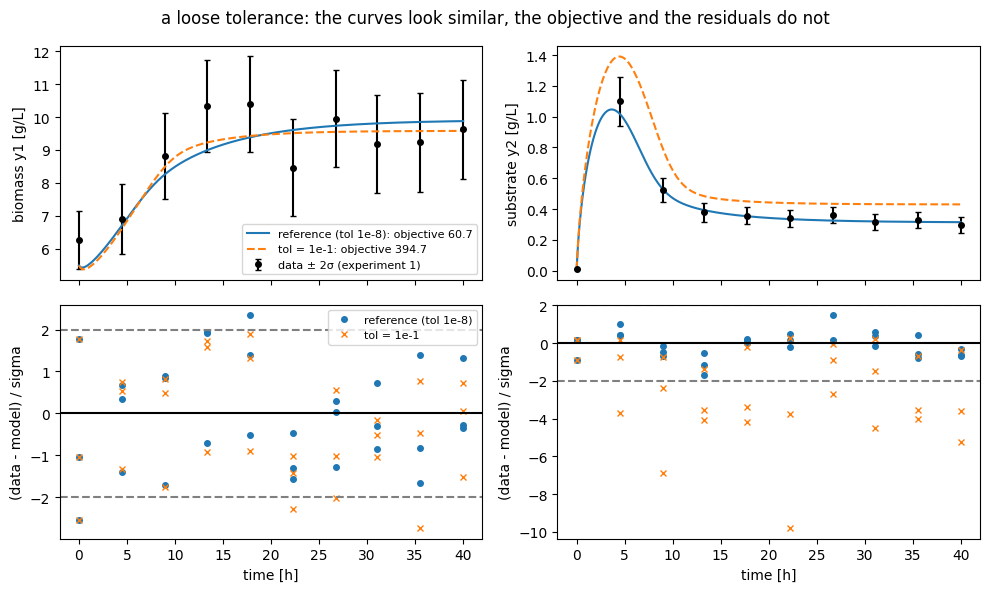

In [17]:
# The reference fit and the early stop: curves of experiment 1 with each objective in the legend
# (top), weighted residuals of all experiments (bottom)
compare = ['reference (tol 1e-8)', 'tol = 1e-1']
fig, ax = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for i, y in enumerate(['y1', 'y2']):
    sheet = data['1']
    ax[0, i].errorbar(sheet[f'MES_X:{y}'], sheet[f'MES_Y:{y}'], yerr=2 * sheet[f'MES_E:{y}'],
                      fmt='o', color='k', ms=4, capsize=2, label='data ± 2σ (experiment 1)')
    for k, label in enumerate(compare):
        t, out = simulate(sheet, curves[label])
        ax[0, i].plot(t, out[y], ls=['-', '--'][k], color=f'C{k}',
                      label=f'{label}: objective {stopped[label][2]}')
        for name, sh in data.items():                  # weighted residuals, every experiment
            t, out = simulate(sh, curves[label])
            model_at_samples = np.interp(sh[f'MES_X:{y}'], t, out[y])
            weighted = (sh[f'MES_Y:{y}'] - model_at_samples) / sh[f'MES_E:{y}']
            ax[1, i].plot(sh[f'MES_X:{y}'], weighted, ['o', 'x'][k], color=f'C{k}', ms=4,
                          label=label if name == '1' else None)
    ax[0, i].set(ylabel=f"{['biomass', 'substrate'][i]} {y} [g/L]")
    for level in (-2, 2):
        ax[1, i].axhline(level, ls='--', color='gray')
    ax[1, i].axhline(0, color='k')
    ax[1, i].set(xlabel='time [h]', ylabel='(data - model) / sigma')
ax[0, 0].legend(fontsize=8)
ax[1, 0].legend(fontsize=8)
fig.suptitle('a loose tolerance: the curves look similar, the objective and the residuals do not')
plt.tight_layout(); plt.show()

**What to look for:**

- With a loose `tol` the optimiser reports **success**, yet the objective is 1.3 times (`tol = 1e-2`)
  and 6.5 times (`tol = 1e-1`) the reference, and the estimates are off by up to ~60 % ($m$). "Converged" only means "stopped by my
  criterion".
- With a small `maxit` it says so (`success = False`). Read `message`.
- The biomass curves (top left) look alike; the substrate curve of the early stop is off, but only by
  a fraction of a g/L. The objective in the legend (395 against 61) and the weighted residuals (bottom)
  show it plainly: most substrate residuals of the early stop lie below −2, a systematic bias rather
  than random scatter around 0. So **compare objective values** and look at the residuals. Rerun with
  a tighter `tol` or another method: if the objective drops, the first fit had not finished.

### 6.3 Objectives

Sums over all measured points $i$ of all outputs, with residual $r_i = y_i - \hat y_i$ and the σ of
each point from the `MES_E` column:

| `ob` | Formula | Assumes | Use when | Consequence |
|---|---|---|---|---|
| `'WLS'` | $\sum (r_i/\sigma_i)^2$ | known σ per point | you know σ (the usual choice) | each point counts by its precision |
| `'MLE'` | $\tfrac12 \sum [\ln(2\pi\sigma_i^2) + (r_i/\sigma_i)^2]$ (paper eq. S6) | known σ, normal errors | as WLS | with known σ the same estimates as WLS; only the value differs (it can be negative) |
| `'LS'` | $\sum r_i^2$ | the same σ for every point | outputs of similar size and precision | large outputs dominate; σ is ignored |
| `'Chi'` | $\sum \big(r_i/\max(\lvert y_i\rvert, \sigma_i)\big)^2$ (relative LS) | σ proportional to the measured value | relative errors | **[MIDDoE extra]** $\lvert y_i\rvert$ is floored at the point's σ, so a value measured near 0 (below the noise) gets the weight $1/\sigma_i^2$, not an unbounded one. Still the wrong weighting for absolute errors (Part 8.3) |

In [18]:
objectives, fits_ob = {}, {}
for objective in ['WLS', 'MLE', 'LS', 'Chi']:
    fit_o = parmest(system, copy.deepcopy(models_start), dict(iden_opt, ob=objective))['MI']
    error = 100 * (np.array(fit_o['scpr']) - theta_true) / theta_true
    objectives[objective] = list(np.round(fit_o['scpr'], 4)) + [round(np.abs(error).mean(), 1)]
    fits_ob[objective] = fit_o['scpr']
pd.DataFrame(objectives, index=NAMES + ['mean |error| vs true [%]']).T

[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx


,mu_max,Ks,Yxs,m,mean |error| vs true [%]
WLS,0.2285,0.2925,0.7883,0.0681,15.1
MLE,0.2285,0.2925,0.7883,0.0681,15.1
LS,0.2365,0.2406,0.8291,0.0746,8.0
Chi,0.2260,0.2930,0.7697,0.0663,16.4


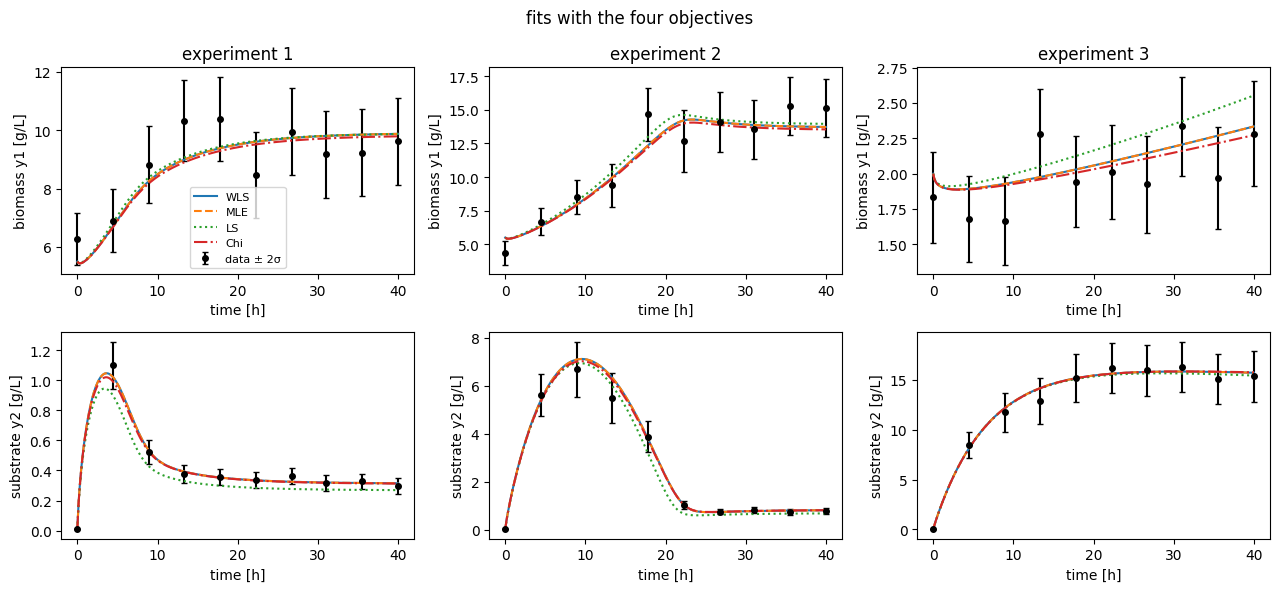

In [19]:
plot_fit(fits_ob, title='fits with the four objectives')

- `'MLE'` gives the WLS estimates, as expected with known σ: in the plot its dashed curve lies on top
  of WLS. Only the objective value differs.
- `'LS'` ignores σ. The biomass values are about 10 times larger than the substrate values, so the
  biomass dominates the fit and the substrate data, which carry most of the information on $K_s$,
  hardly count. With this particular noise draw LS happens to land closer to the truth than WLS:
  one data set proves nothing (Part 8 shows how much estimates move between draws). What matters is
  the precision you can *claim*, and Part 7.2 shows that LS determines $K_s$ about 4 times less
  precisely.
- `'Chi'` weights each point by $1/y_i^2$. That is WLS with σ proportional to the *measured* value, so
  with relative errors, as here, it lands close to WLS. With absolute errors it weights the points
  wrongly (Part 8.3 shows it).
- In the plot the fits are nearly indistinguishable: all objectives fit these data well. They
  differ in **which points they trust most**, and that shows up in the estimates and their precision,
  not in the picture.

### 6.4 Fixing a parameter

Set `mutation` to `False` for a parameter to keep it at its `theta` value. This is what you do when a
parameter cannot be estimated from the data (estimability analysis, a later tutorial). Here we fix
the maintenance coefficient $m$ at its (wrong) starting value 0.108. The other parameters compensate,
so they move away from their true values: **fixing a parameter at a wrong value biases the others.**

In [20]:
models_fixed = copy.deepcopy(models_start)
models_fixed['mutation']['MI'] = [True, True, True, False]
fit_f = parmest(system, models_fixed, iden_opt)['MI']
print(f"objective: all free {fit['fun']:.1f}   m fixed {fit_f['fun']:.1f}")
pd.DataFrame({'all free': fit['scpr'], 'm fixed': fit_f['scpr'], 'true': theta_true}, index=NAMES)

[INFO] Reading from data.xlsx


objective: all free 60.7   m fixed 74.5


,all free,m fixed,true
mu_max,0.228549,0.269024,0.25
Ks,0.292463,0.235559,0.25
Yxs,0.788307,0.968577,0.88
m,0.068070,0.108000,0.09


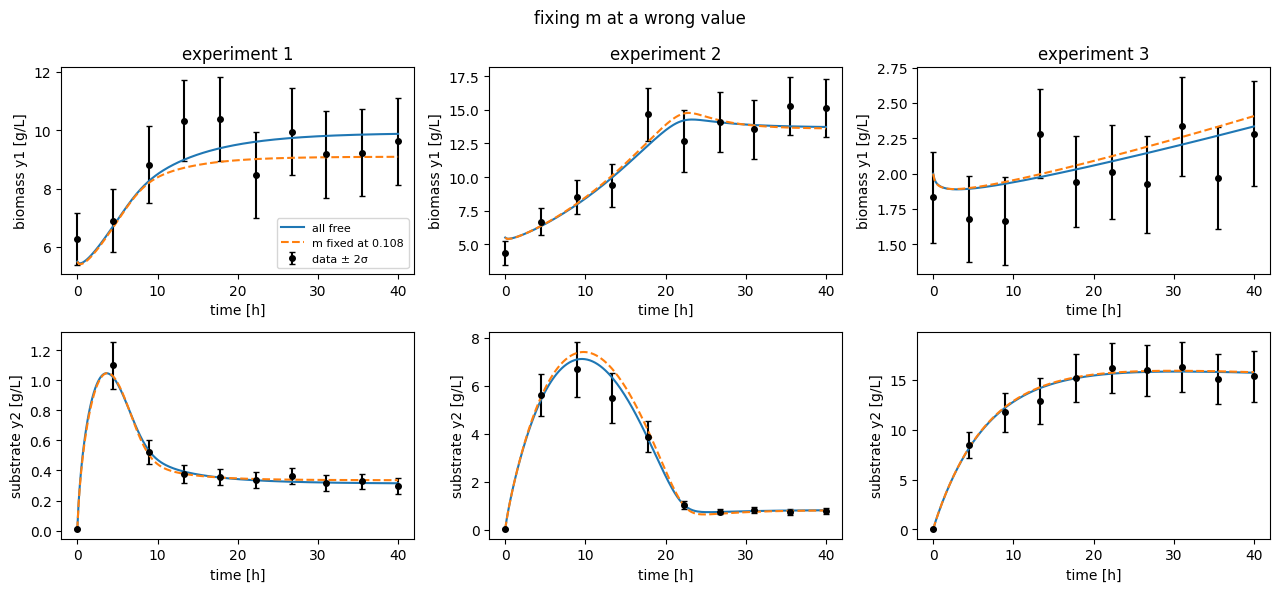

In [21]:
plot_fit({'all free': fit['scpr'], 'm fixed at 0.108': fit_f['scpr']}, title='fixing m at a wrong value')

**What to look for:** the curves with $m$ fixed are only slightly worse, because the other three
parameters compensate. A worse objective and slightly poorer curves can hide strongly biased
parameters. Fix a parameter only at a value you trust (literature, a separate experiment).

---
## Part 7. Uncertainty analysis: `uncert`

`uncert(resultpr, system, models, iden_opt)` answers the question: **how precise are the estimates?**
It computes the following for each model:

| Output (`['results']['MI'][...]`) | Meaning |
|---|---|
| `estimations` | the estimates (same as `scpr`) |
| `V_matrix` | variance–covariance matrix $V$ of the free parameters |
| `CI` | 95 % confidence half-width: $CI_i = t_{0.975,\,dof}\sqrt{V_{ii}}$ |
| `t_values` | $t_i = \hat\theta_i / \sqrt{V_{ii}}$; the parameter is **precise** when $t_i > t_{ref}$ |
| `R2_responses`, `R2_total` | how well the fit follows the data, per output and overall |
| `LS`, `WLS`, `MLE`, `Chi`, `MSE` | all objective values at the estimate |
| `P` | P-test probability (paper eq. 2) that this model is the best among `can_m`; 100 % with a single model |
| `LSA` | sensitivities $\partial y/\partial\theta$ of every measured point (used by designs and estimability) |

`['obs']` is the number of measured points $N$. The reference $t_{ref} = t_{0.975,\,N - N_\theta}$ is
the Student-t value with $N$ minus the number of free parameters as degrees of freedom.

**`case` argument.** With `case=None` (default), `uncert` also **updates `models`**: `theta` becomes the
estimate, plus `V_matrix`, `LSA` and `thetastart`. The next design then starts from the new estimate.
Any other value, e.g. `case='check'`, leaves `models` untouched. We use `'check'` for all the
comparisons below.

In [22]:
# uncert(resultpr, system, models, iden_opt, case=None, data=None)
#   resultpr: the output of parmest
#   case:     None = also UPDATE models (theta <- estimate, V_matrix, LSA, thetastart);
#             any other value, e.g. 'check' = leave models untouched (used for comparisons below)
#   data:     as in parmest (None = data.xlsx)
unc = uncert(resultpr, system, models, iden_opt)
res = unc['results']['MI']
t_ref = student_t.ppf(0.975, unc['obs'] - 4)       # N - number of free parameters

print('measured points N =', unc['obs'], '| t_ref =', round(t_ref, 3),
      '| R2 =', round(res['R2_total'], 4), '| P =', res['P'], '%')
pd.DataFrame({'estimate': res['estimations'], '95% CI (+/-)': res['CI'], 't-value': res['t_values'],
              'passes t-test': res['t_values'] > t_ref, 'true': theta_true}, index=NAMES)

[INFO] Reading from data.xlsx
active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.45e+01, cond(M)≈7.15e+03, λ_min(M)≈4.00e+01; OK


CI: [0.01851409 0.03481761 0.08541448 0.01814945]
measured points N = 60 | t_ref = 2.003 | R2 = 0.9868 | P = 100.0 %


,estimate,95% CI (+/-),t-value,passes t-test,true
mu_max,0.228549,0.018514,24.729169,True,0.25
Ks,0.292463,0.034818,16.826923,True,0.25
Yxs,0.788307,0.085414,18.488293,True,0.88
m,0.068070,0.018149,7.513193,True,0.09


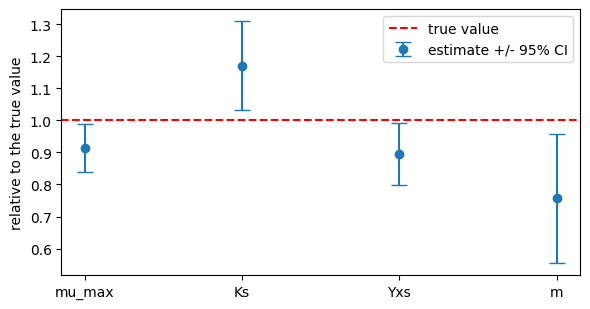

In [23]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.errorbar(range(4), np.array(res['estimations']) / theta_true, yerr=np.array(res['CI']) / theta_true,
            fmt='o', capsize=6, label='estimate +/- 95% CI')
ax.axhline(1, color='r', ls='--', label='true value')
ax.set_xticks(range(4), NAMES); ax.set_ylabel('relative to the true value'); ax.legend()
plt.tight_layout(); plt.show()

All four parameters pass the t-test: the data determine them well. The maintenance coefficient $m$
has the smallest t-value, so it is the hardest to determine from these experiments.

**Are the true values inside the intervals?** With this noise draw, each true value lies just outside
its own interval. That looks wrong, but the intervals above treat each parameter **separately**.
The parameters are strongly **correlated** ($\mu_{max}$, $Y_{xs}$ and $m$ partly compensate each
other), so one unlucky noise draw shifts them together. The right check is **joint**: the true vector
lies inside the 95 % confidence ellipsoid when

$$ D^2 = (\hat\theta - \theta_{true})^T\, V^{-1}\, (\hat\theta - \theta_{true}) \;<\; \chi^2_{0.95,\,4} = 9.49 $$

In [24]:
difference = np.array(res['estimations']) - theta_true
D2 = difference @ np.linalg.inv(res['V_matrix']) @ difference
print(f'D2 = {D2:.2f}   limit chi2(0.95, 4) = {chi2.ppf(0.95, 4):.2f}   ->  truth inside the joint region: {D2 < chi2.ppf(0.95, 4)}')
print('correlation matrix:')
sd = np.sqrt(np.diag(res['V_matrix']))
pd.DataFrame(res['V_matrix'] / np.outer(sd, sd), index=NAMES, columns=NAMES).round(2)

D2 = 6.88   limit chi2(0.95, 4) = 9.49   ->  truth inside the joint region: True
correlation matrix:


,mu_max,Ks,Yxs,m
mu_max,1.00,-0.87,0.98,1.00
Ks,-0.87,1.00,-0.87,-0.90
Yxs,0.98,-0.87,1.00,0.97
m,1.00,-0.90,0.97,1.00


The true values are inside the joint 95 % region. The correlation matrix shows why the single
intervals miss: correlations close to ±1 mean the data fix a *combination* of parameters much better
than each one alone. $\mu_{max}$ and $m$ are almost perfectly correlated (1.00): a faster growth
with a larger maintenance gives nearly the same curves, so these experiments cannot tell them apart
well. Designing a better experiment (next tutorial) can break such correlations. The confidence ellipses in Part 9 show the same picture. Part 8 repeats the
study with other noise draws.

### 7.1 Covariance methods

| `var-cov` | Method | Cost | Notes |
|---|---|---|---|
| `'M'` | Fisher information: $V = (Q^T \Sigma^{-1} Q)^{-1}$ from the sensitivities $Q$ and the σ of each point | fast | linear approximation around the estimate. Always uses the σ of the data, whatever the objective |
| `'H'` | inverse **Hessian** (curvature) of the objective at the optimum | fast | describes the objective you actually minimised. Scaled to it: $V=2H^{-1}$ (WLS), $H^{-1}$ (MLE), $2\,\tfrac{J}{N-N_\theta}H^{-1}$ (LS, Chi). **[MIDDoE extra]** computed in "whitened" coordinates, so it stays accurate for strongly correlated parameters. Needs a true minimum: if it is not positive definite, CI and t of the affected parameters are NaN, with a warning |
| `'B'` | **bootstrap**: refit `nboot` times on data resampled with replacement (individual points) and take the spread of the estimates | slow: `nboot` fits, in parallel | no linearity assumption. **[MIDDoE extra]** corrected for the parameter bounds with a truncated-normal fit. Needs many repetitions (the paper uses 500 in Case Study 2) |

For a well-determined model all three should give similar intervals. `'H'` and `'B'` need `parmest`
to run with that option, so we run `parmest` again for each.

In [25]:
ci = {}
for method, nboot in [('M', None), ('H', None), ('B', 10), ('B', 100)]:
    opt = dict(iden_opt, **{'var-cov': method})
    if nboot:
        opt['nboot'] = nboot
    start = time.time()
    fit_v = parmest(system, copy.deepcopy(models_start), opt)
    out = uncert(fit_v, system, models, opt, case='check')['results']['MI']
    label = method + (f' (nboot={nboot})' if nboot else '')
    ci[label] = list(np.round(out['CI'], 4)) + [round(time.time() - start)]
    if nboot == 100:
        boot_samples = fit_v['MI']['X']          # one row of estimates per bootstrap repetition
ci_table = pd.DataFrame(ci, index=[f'CI {n}' for n in NAMES] + ['time [s]'])
ci_table

[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx
active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.45e+01, cond(M)≈7.15e+03, λ_min(M)≈4.00e+01; OK


CI: [0.01851409 0.03481761 0.08541448 0.01814945]
[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx
active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.45e+01, cond(M)≈7.02e+03, λ_min(M)≈4.15e+01; OK


... (6 outputs left out)

INFO:middoe.iden_uncert:Using bootstrap var–cov for MI


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.64e+01, cond(M)≈3.96e+03, λ_min(M)≈3.57e+01; OK


CI: [0.0197536  0.03477393 0.09551277 0.01904226]


,M,H,B (nboot=10),B (nboot=100)
CI mu_max,0.0185,0.0182,0.0122,0.0198
CI Ks,0.0348,0.0341,0.0146,0.0348
CI Yxs,0.0854,0.0841,0.0616,0.0955
CI m,0.0181,0.0178,0.0111,0.0190
time [s],12.0000,21.0000,46.0000,318.0000


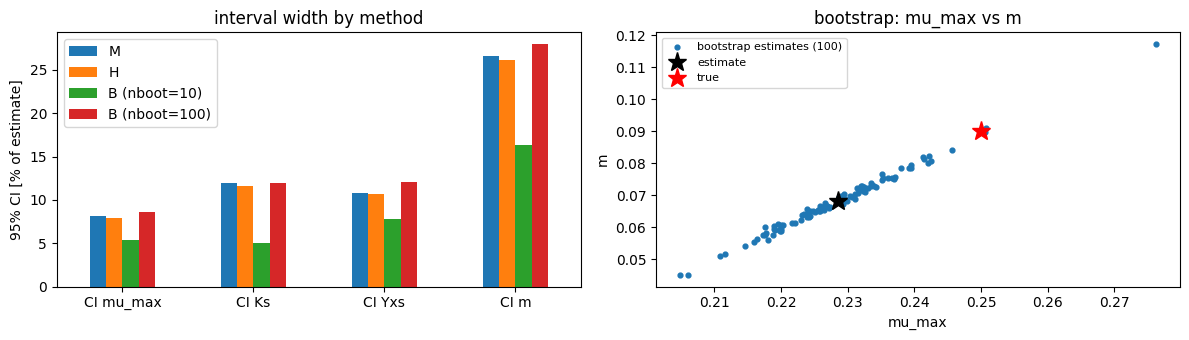

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
(ci_table.iloc[:4].div(res['estimations'], axis=0) * 100).plot.bar(ax=ax[0], rot=0)
ax[0].set(ylabel='95% CI [% of estimate]', title='interval width by method')

ax[1].scatter(boot_samples[:, 0], boot_samples[:, 3], s=12, label='bootstrap estimates (100)')
ax[1].plot(res['estimations'][0], res['estimations'][3], 'k*', ms=14, label='estimate')
ax[1].plot(theta_true[0], theta_true[3], 'r*', ms=14, label='true')
ax[1].set(xlabel='mu_max', ylabel='m', title='bootstrap: mu_max vs m'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

- `'M'` and `'H'` agree closely: the fit is good, σ is known and the model is nearly linear around
  the estimate.
- `parmest` prints how many bootstrap repetitions it kept. **[MIDDoE extra]** A repetition is dropped
  if its optimum is more than twice the reference optimum: refitting a resample of the same data
  should give an objective of the same size, so a much larger one means that fit stopped before the
  minimum. Kept stalled fits would widen the intervals for no statistical reason.
- The bootstrap needs enough repetitions. With 10 its intervals are rough; with 100 they settle. Large
  differences between `'B'` and `'M'`/`'H'` would point to a strongly nonlinear model or a poor fit;
  then trust the bootstrap.
- **The scatter plot shows the correlation directly.** Each point is one refit on resampled data. The
  points lie along a line: when $\mu_{max}$ comes out higher, $m$ comes out higher too. Along that line
  the data cannot decide well; across it they can. The true value lies along the line, which is why
  the joint check above passes even though the single intervals miss.

### 7.2 Objective and covariance together

`'M'` describes a weighted fit with the σ of the data, whatever objective was minimised. `'H'`
describes the objective that was actually minimised. So the pair must be consistent.

In [27]:
pairs = {}
for objective in ['WLS', 'MLE', 'LS', 'Chi']:
    for method in ['M', 'H']:
        opt = dict(iden_opt, ob=objective, **{'var-cov': method})
        out = uncert(parmest(system, copy.deepcopy(models_start), opt), system, models, opt, case='check')['results']['MI']
        pairs[f'{objective} + {method}'] = np.round(out['CI'], 4)
pairs_table = pd.DataFrame(pairs, index=[f'CI {n}' for n in NAMES]).T
pairs_table

[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx
active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.45e+01, cond(M)≈7.15e+03, λ_min(M)≈4.00e+01; OK


CI: [0.01851409 0.03481761 0.08541448 0.01814945]
[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx
active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.45e+01, cond(M)≈7.02e+03, λ_min(M)≈4.15e+01; OK


... (16 outputs left out)

[INFO] Reading from data.xlsx
active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.33e+01, cond(M)≈5.85e+03, λ_min(M)≈4.30e+01; OK


CI: [0.01761971 0.03362992 0.07991955 0.01718123]


,CI mu_max,CI Ks,CI Yxs,CI m
WLS + M,0.0185,0.0348,0.0854,0.0181
WLS + H,0.0182,0.0341,0.0841,0.0178
MLE + M,0.0185,0.0348,0.0854,0.0181
MLE + H,0.0182,0.0341,0.0840,0.0178
LS + M,0.0201,0.0305,0.0930,0.0197
LS + H,0.0246,0.1302,0.1135,0.0230
Chi + M,0.0183,0.0349,0.0835,0.0179
Chi + H,0.0176,0.0336,0.0799,0.0172


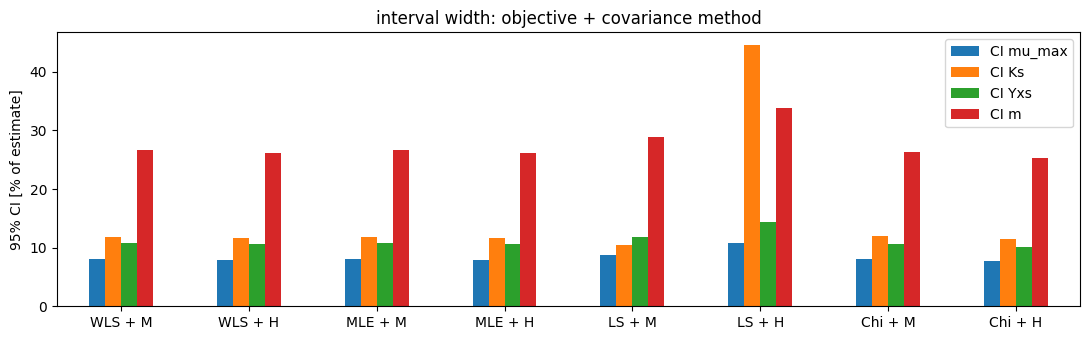

In [28]:
(pairs_table.div(res['estimations'], axis=1) * 100).plot.bar(figsize=(11, 3.5), rot=0)
plt.ylabel('95% CI [% of estimate]'); plt.title('interval width: objective + covariance method')
plt.tight_layout(); plt.show()

- **WLS/MLE**: `'M'` and `'H'` agree.
- **LS**: the fit ignores σ and the substrate data hardly count, so $K_s$ is poorly determined by this
  estimator. `'H'` shows that (a wide $K_s$ interval); `'M'` does not, because it assumes the
  σ-weighted information. A bootstrap of the LS fit confirms the wide $K_s$ interval.
  **With `'LS'`, use `'H'` or `'B'`.**
- **Chi**: relative weighting matches relative errors here, so both are close to WLS.

### 7.3 Sensitivity settings (`sens_m`, `eps`) for `'M'`

The Fisher matrix needs the sensitivities $\partial y/\partial\theta$, computed by finite differences
on the scaled parameters:

| Option | Values | Consequence |
|---|---|---|
| `sens_m` | `'central'` (2 runs per parameter, error $\propto \varepsilon^2$), `'forward'` (1 run, error $\propto \varepsilon$) | central is more accurate, forward is cheaper |
| `eps` | a number (relative step), or `None` | too large: truncation error; too small: solver noise dominates. **[MIDDoE extra]** `None` searches for a step where the sensitivities are stable (costs extra model runs; the step found is stored in `found_eps`) |

In [29]:
sens = {}
for sens_m, eps in [('central', 1e-3), ('forward', 1e-3), ('central', 1e-5), ('central', None)]:
    opt = dict(iden_opt, sens_m=sens_m, eps=eps)
    out = uncert(resultpr, system, models, opt, case='check')['results']['MI']
    sens[f'{sens_m}, eps={eps}'] = np.round(out['CI'], 5)
pd.DataFrame(sens, index=[f'CI {n}' for n in NAMES]).T

[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.45e+01, cond(M)≈7.15e+03, λ_min(M)≈4.00e+01; OK


CI: [0.01851409 0.03481761 0.08541448 0.01814945]
[INFO] Reading from data.xlsx
active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.06e+01, cond(M)≈6.50e+03, λ_min(M)≈4.26e+01; OK


CI: [0.0182697  0.03396363 0.08133733 0.01759635]
[INFO] Reading from data.xlsx
active_idx: [0 1 2 3]


... (104 outputs left out)

active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.45e+01, cond(M)≈7.15e+03, λ_min(M)≈3.99e+01; OK


CI: [0.01851951 0.03482124 0.0854298  0.01815352]


,CI mu_max,CI Ks,CI Yxs,CI m
"central, eps=0.001",0.01851,0.03482,0.08541,0.01815
"forward, eps=0.001",0.01827,0.03396,0.08134,0.01760
"central, eps=1e-05",0.01846,0.03475,0.08520,0.01810
"central, eps=None",0.01852,0.03482,0.08543,0.01815


The central-difference settings agree to about 3 digits, whatever the step. Forward differences
are a few % off, the price of their first-order error. A large difference between steps would mean
the step is badly chosen for your model; then use `eps=None`, which costs a few extra model runs.

### 7.4 Less data

**[MIDDoE extra]** With `data=...` we fit experiment 1 only. The confidence intervals widen and the
t-values drop. That is the reason for adding experiments: model-based design (next tutorial) chooses
the experiment that shrinks them fastest.

In [30]:
only_1 = {'1': data['1']}
res_1 = uncert(parmest(system, copy.deepcopy(models_start), iden_opt, data=only_1),
               system, models, iden_opt, case='check', data=only_1)['results']['MI']
t_ref_1 = student_t.ppf(0.975, 20 - 4)               # experiment 1 has 2 x 10 points
pd.DataFrame({'CI, 3 experiments': res['CI'], 'CI, experiment 1 only': res_1['CI'],
              't, 3 experiments': res['t_values'], 't, experiment 1 only': res_1['t_values'],
              'passes (exp. 1 only)': res_1['t_values'] > t_ref_1}, index=NAMES)

active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈4.19e+01, cond(M)≈1.75e+03, λ_min(M)≈1.18e+01; OK


CI: [0.05854289 0.07695406 0.28827311 0.04858103]


,"CI, 3 experiments","CI, experiment 1 only","t, 3 experiments","t, experiment 1 only",passes (exp. 1 only)
mu_max,0.018514,0.058543,24.729169,9.861594,True
Ks,0.034818,0.076954,16.826923,6.805541,True
Yxs,0.085414,0.288273,18.488293,7.483526,True
m,0.018149,0.048581,7.513193,4.597932,True


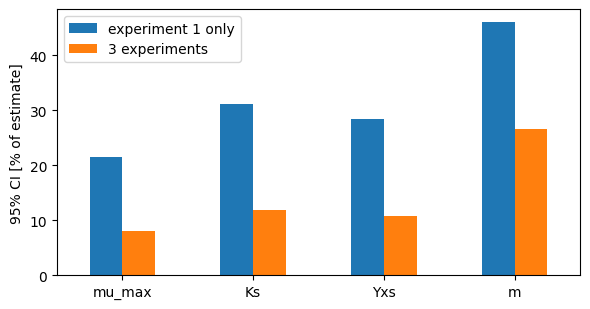

In [31]:
fig, ax = plt.subplots(figsize=(6, 3.2))
pd.DataFrame({'experiment 1 only': np.array(res_1['CI']) / res_1['estimations'] * 100,
              '3 experiments': np.array(res['CI']) / res['estimations'] * 100}, index=NAMES).plot.bar(ax=ax, rot=0)
ax.set_ylabel('95% CI [% of estimate]'); plt.tight_layout(); plt.show()

**What to look for:** every interval shrinks with more data, but not equally. $Y_{xs}$ gains most
here. The next tutorial lets MIDDoE choose the
next experiment so that the worst-determined parameter gains most.

---
## Part 8. Error types and noise levels

How much can we learn from the same three experiments if the instrument is better or worse, if its
error is absolute instead of relative, or if we declare the wrong σ? We repeat the study for several
settings with two small helpers. They do exactly what Parts 4–7 did:

- `make_data(name, errt, unc, ...)` creates the three experiments of Part 4 with another noise
  setting, in its own folder `error_study/<name>/data.xlsx`, and returns `system` and the data.
- `fit_row(system, data, ob)` runs `parmest` + `uncert` (Fisher) and returns one row of results:
  - the estimates;
  - the CI of each parameter in % of its estimate;
  - the mean error against the truth;
  - how many parameters pass the t-test;
  - the joint distance $D^2$ (truth inside the 95 % region when $D^2 < 9.49$).

In [32]:
datasets = {}

def make_data(name, errt, unc, sigma_floor=None, seed=0):
    folder = HERE / 'error_study' / name
    folder.mkdir(parents=True, exist_ok=True)
    os.chdir(folder)                                  # expera() and read_excel() use the working folder
    system_s = copy.deepcopy(system)
    for y in system_s['tvo']:
        system_s['tvo'][y]['unc'] = unc               # noise level of every output
    insilicos_s = dict(insilicos, errt=errt)          # error type
    if sigma_floor is not None:
        insilicos_s['sigma_floor'] = sigma_floor
    if not (folder / 'data.xlsx').exists():           # make the data only once
        np.random.seed(seed)
        for experiment in [1, 2, 3]:
            expera(system_s, models_start, insilicos_s, {}, expr=experiment)
    data_s = read_excel()
    os.chdir(HERE)
    datasets[name] = data_s
    return system_s, data_s


def fit_row(system_s, data_s, ob='WLS'):
    opt = dict(iden_opt, ob=ob)
    out = uncert(parmest(system_s, copy.deepcopy(models_start), opt, data=data_s),
                 system_s, models_start, opt, case='check', data=data_s)
    r = out['results']['MI']
    est, ci_s = np.array(r['estimations']), np.array(r['CI'])
    difference = est - theta_true
    return {**dict(zip(NAMES, np.round(est, 4))),
            **{f'CI {n} [%]': round(100 * c / e, 1) for n, c, e in zip(NAMES, ci_s, est)},
            'mean |error| [%]': round(100 * np.mean(np.abs(difference) / theta_true), 1),
            't-tests passed': int(np.sum(r['t_values'] > student_t.ppf(0.975, out['obs'] - 4))),
            'D2 (< 9.49 = truth inside)': round(float(difference @ np.linalg.pinv(r['V_matrix']) @ difference), 2)}

### 8.1 Noise level and error type

The relative 8 % case reproduces the data of Parts 4–7 (same seed).

[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.02_seed0\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.02
   - y2         | measurable      | std.dev = 0.02


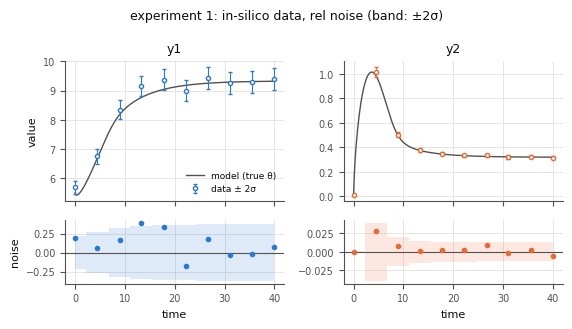

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.02_seed0\data_plots\experiment_1.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.02_seed0\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.02
   - y2         | measurable      | std.dev = 0.02


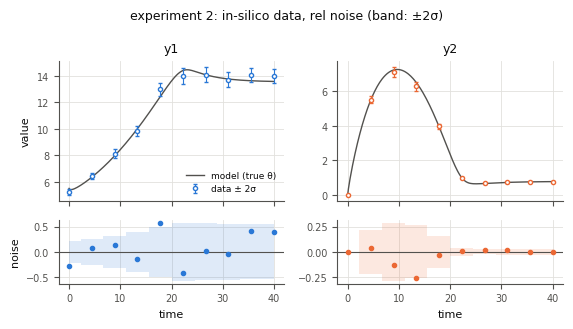

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.02_seed0\data_plots\experiment_2.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.02_seed0\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.02
   - y2         | measurable      | std.dev = 0.02


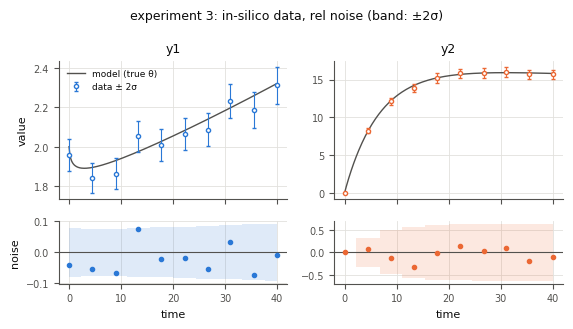

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.02_seed0\data_plots\experiment_3.png
[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈9.74e+01, cond(M)≈9.48e+03, λ_min(M)≈6.39e+02; OK


CI: [0.00545375 0.00839675 0.02481657 0.00536102]
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed0\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


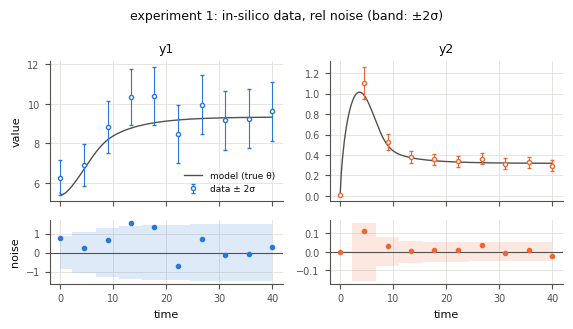

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed0\data_plots\experiment_1.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed0\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


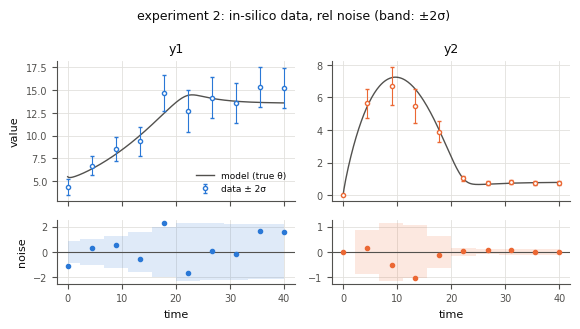

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed0\data_plots\experiment_2.png


[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed0\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


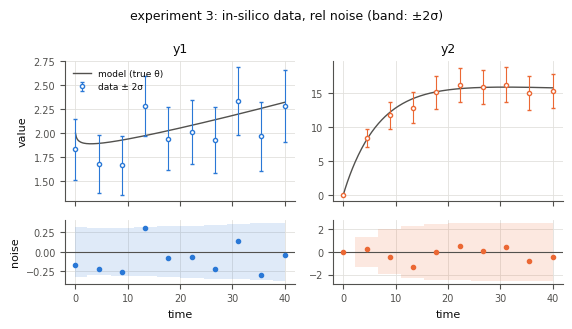

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed0\data_plots\experiment_3.png
[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.45e+01, cond(M)≈7.15e+03, λ_min(M)≈4.00e+01; OK


CI: [0.01851409 0.03481761 0.08541448 0.01814945]
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.2_seed0\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.2
   - y2         | measurable      | std.dev = 0.2


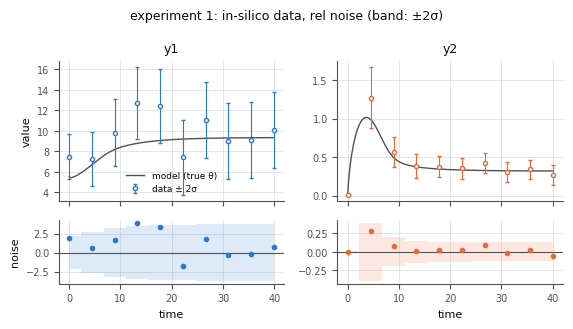

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.2_seed0\data_plots\experiment_1.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.2_seed0\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.2
   - y2         | measurable      | std.dev = 0.2


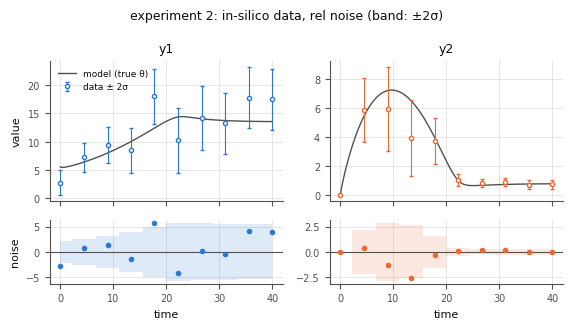

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.2_seed0\data_plots\experiment_2.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.2_seed0\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.2
   - y2         | measurable      | std.dev = 0.2


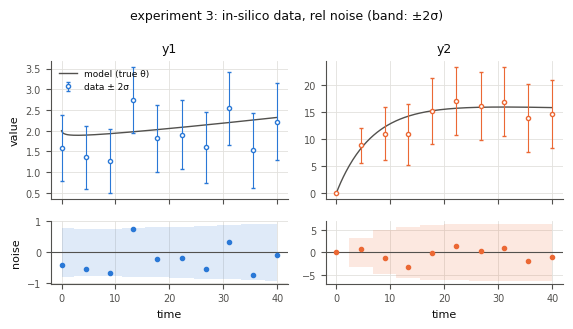

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.2_seed0\data_plots\experiment_3.png
[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈7.43e+01, cond(M)≈5.52e+03, λ_min(M)≈5.42e+00; OK


CI: [0.03586292 0.09388551 0.16959079 0.03496055]
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_floor\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


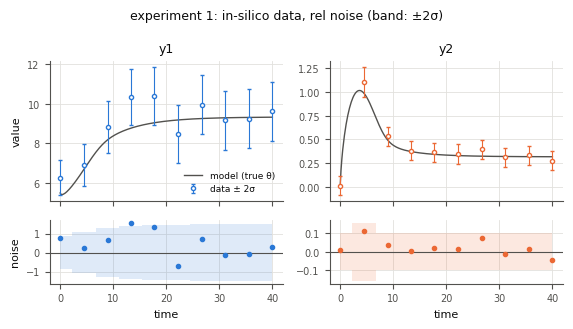

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_floor\data_plots\experiment_1.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_floor\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


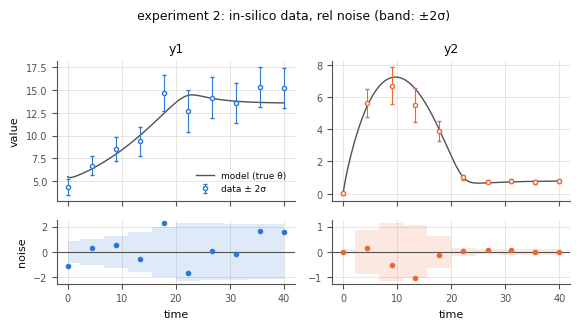

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_floor\data_plots\experiment_2.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_floor\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


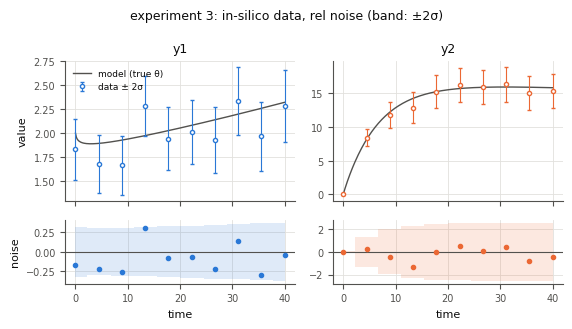

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_floor\data_plots\experiment_3.png
[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.97e+01, cond(M)≈8.05e+03, λ_min(M)≈3.39e+01; OK


CI: [0.02010438 0.03656673 0.09064931 0.01956258]
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.08_seed0\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


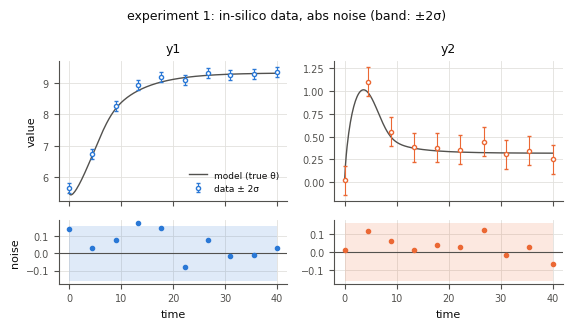

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.08_seed0\data_plots\experiment_1.png


[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.08_seed0\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


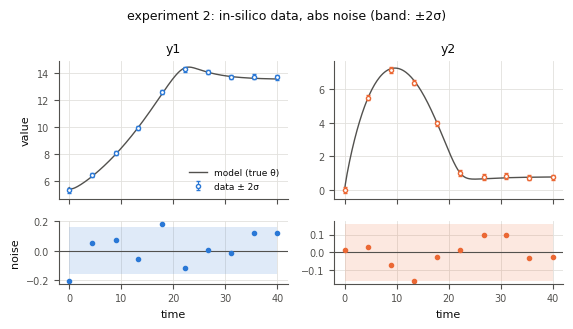

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.08_seed0\data_plots\experiment_2.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.08_seed0\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


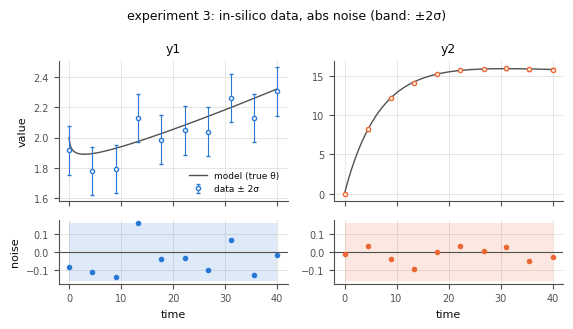

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.08_seed0\data_plots\experiment_3.png
[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈5.58e+01, cond(M)≈3.11e+03, λ_min(M)≈9.58e+02; OK


CI: [0.00368945 0.01583431 0.01677498 0.00349451]
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed0\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.5
   - y2         | measurable      | std.dev = 0.5


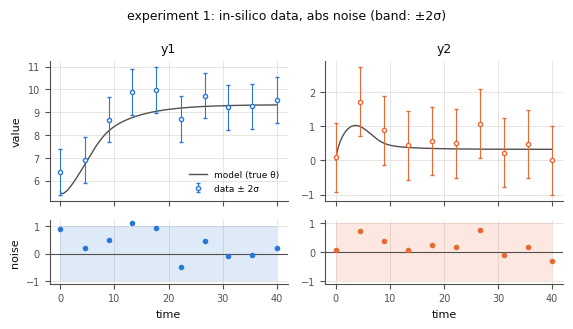

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed0\data_plots\experiment_1.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed0\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.5
   - y2         | measurable      | std.dev = 0.5


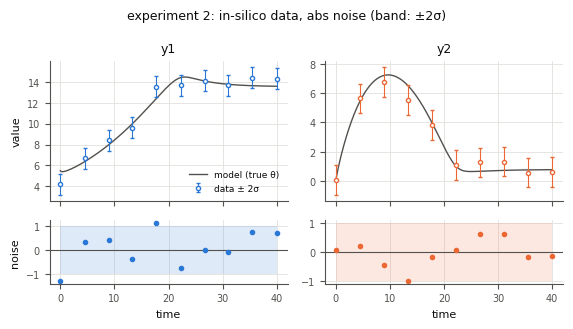

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed0\data_plots\experiment_2.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed0\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.5
   - y2         | measurable      | std.dev = 0.5


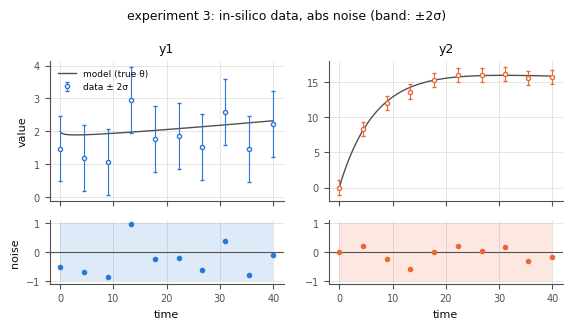

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed0\data_plots\experiment_3.png
[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈5.02e+01, cond(M)≈2.52e+03, λ_min(M)≈2.65e+01; OK


CI: [0.02039214 0.10448707 0.09312974 0.01910978]


,mu_max,Ks,Yxs,m,CI mu_max [%],CI Ks [%],CI Yxs [%],CI m [%],mean |error| [%],t-tests passed,D2 (< 9.49 = truth inside)
rel 2 %,0.2439,0.2608,0.8541,0.0838,2.2,3.2,2.9,6.4,4.1,4.0,6.97
rel 8 % (Parts 4-7),0.2285,0.2925,0.7883,0.0681,8.1,11.9,10.8,26.7,15.1,4.0,6.88
rel 20 %,0.2063,0.3542,0.6924,0.0451,17.4,26.5,24.5,77.5,32.6,4.0,8.18
"rel 8 %, floor 0.05",0.2269,0.2949,0.7816,0.0664,8.9,12.4,11.6,29.4,16.1,4.0,7.14
abs 0.08 g/L,0.2476,0.2559,0.8696,0.0874,1.5,6.2,1.9,4.0,1.9,4.0,5.71
abs 0.5 g/L,0.2374,0.2818,0.8241,0.0756,8.6,37.1,11.3,25.3,10.0,4.0,6.27


In [33]:
noise_settings = {                     # label: (folder, errt, unc, sigma_floor)
    'rel 2 %':             ('rel_0.02_seed0', 'rel', 0.02, None),
    'rel 8 % (Parts 4-7)': ('rel_0.08_seed0', 'rel', 0.08, None),
    'rel 20 %':            ('rel_0.2_seed0',  'rel', 0.20, None),
    'rel 8 %, floor 0.05': ('rel_0.08_floor', 'rel', 0.08, 0.05),
    'abs 0.08 g/L':        ('abs_0.08_seed0', 'abs', 0.08, None),
    'abs 0.5 g/L':         ('abs_0.5_seed0',  'abs', 0.50, None),
}
regimes = {label: fit_row(*make_data(*setting)) for label, setting in noise_settings.items()}
regimes_table = pd.DataFrame(regimes).T
regimes_table

First **look at the data**: the substrate of experiment 1 under four settings.

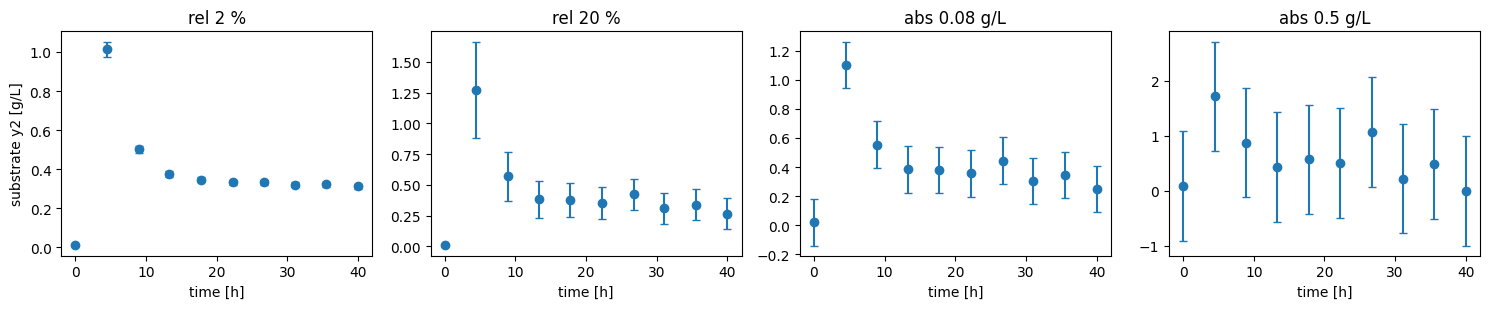

In [34]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for a, label in zip(ax, ['rel 2 %', 'rel 20 %', 'abs 0.08 g/L', 'abs 0.5 g/L']):
    sheet = datasets[noise_settings[label][0]]['1']
    a.errorbar(sheet['MES_X:y2'], sheet['MES_Y:y2'], yerr=2 * sheet['MES_E:y2'], fmt='o', capsize=3)   # +/- 2 sigma
    a.set(title=label, xlabel='time [h]')
ax[0].set_ylabel('substrate y2 [g/L]')
plt.tight_layout(); plt.show()

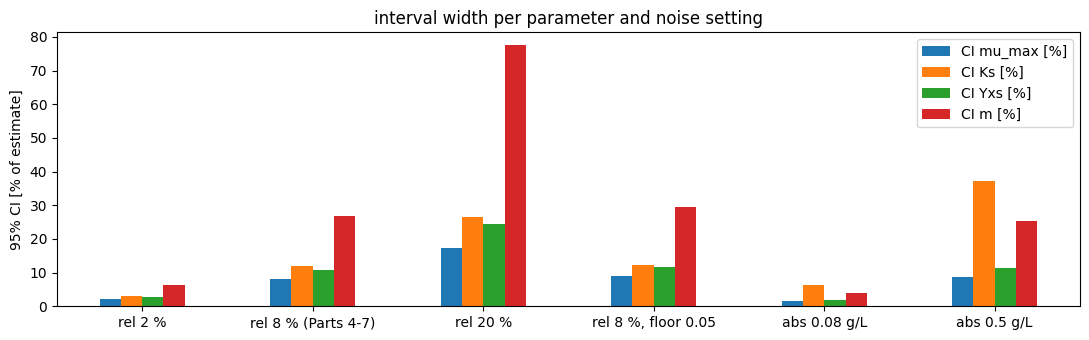

In [35]:
ci_columns = [f'CI {n} [%]' for n in NAMES]
regimes_table[ci_columns].astype(float).plot.bar(figsize=(11, 3.5), rot=0)
plt.ylabel('95% CI [% of estimate]'); plt.title('interval width per parameter and noise setting')
plt.tight_layout(); plt.show()

What the plots show:

- **Noise level.** With relative errors every interval grows with the noise: about 4 times wider from
  2 % to 8 %, and 2–3 times again to 20 %. All parameters still pass the t-test here, but $m$ is at
  78 % with 20 % noise. With more parameters or fewer data the noisiest case would fail first.
- **`sigma_floor`.** Raising the floor from $10^{-6}$ to 0.05 g/L stops the near-zero substrate points
  from claiming an unrealistic precision. The intervals widen slightly: the floor removes information
  that a real instrument would not deliver.
- **Absolute vs relative: the error type changes *which* parameter is well determined.**
  - Compare *abs 0.5 g/L* with *rel 8 %*. $\mu_{max}$, $Y_{xs}$ and $m$ get about the same
    intervals, but $K_s$ goes from 12 % to 37 %. The low substrate values that carry $K_s$ drown in an
    absolute noise of 0.5 g/L (see the data plot), while relative noise keeps them precise.
  - With *abs 0.08 g/L* the biomass (5–15 g/L) is measured to about 1 %, so $\mu_{max}$, $Y_{xs}$
    and $m$ get very narrow intervals (1.5–4 %), and $K_s$ is now the worst determined (6 %).
  - $m$ has the widest relative interval in every relative-error setting: it is the hardest
    parameter for these three experiments.
- **Joint check.** $D^2 < 9.49$ in every case: the truth is inside the joint 95 % region.

### 8.2 Same setting, different noise draws

Repeating the relative 8 % case with other random seeds shows how much the estimates move from one
data set to the next. **That scatter is what the CI predicts.**

[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.45e+01, cond(M)≈7.15e+03, λ_min(M)≈4.00e+01; OK


CI: [0.01851409 0.03481761 0.08541448 0.01814945]
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed1\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


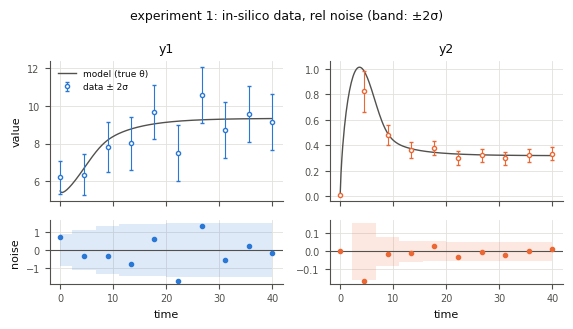

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed1\data_plots\experiment_1.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed1\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


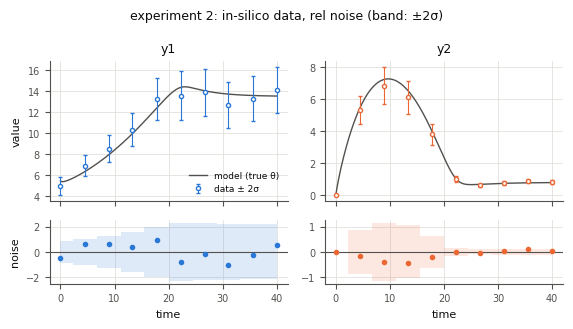

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed1\data_plots\experiment_2.png


[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed1\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


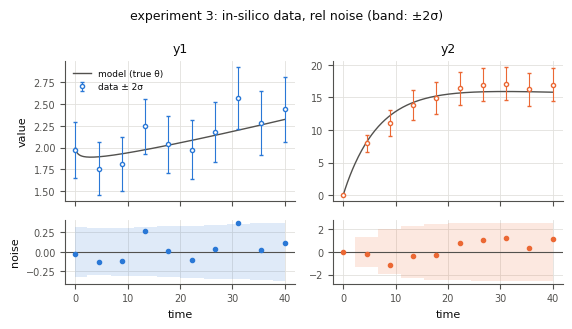

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed1\data_plots\experiment_3.png
[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈9.58e+01, cond(M)≈9.19e+03, λ_min(M)≈3.86e+01; OK


CI: [0.02389737 0.03356053 0.10691925 0.02358112]
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed2\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


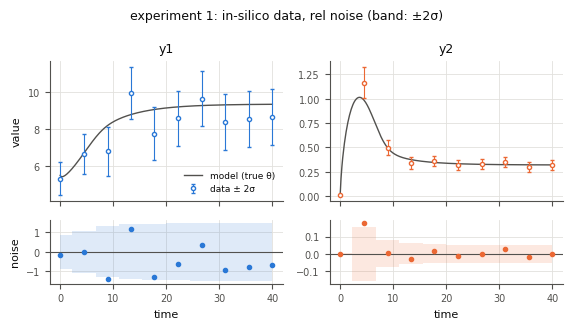

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed2\data_plots\experiment_1.png


[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed2\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


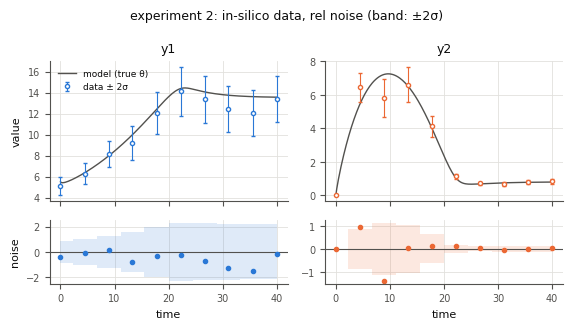

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed2\data_plots\experiment_2.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed2\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


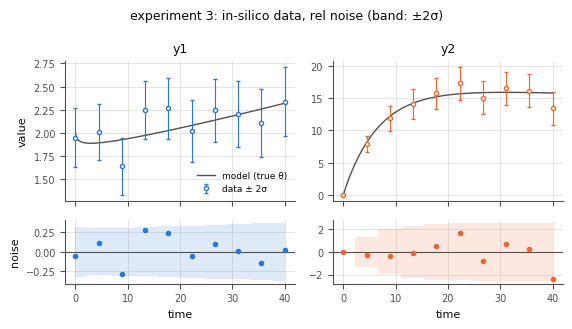

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed2\data_plots\experiment_3.png
[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈1.25e+02, cond(M)≈1.55e+04, λ_min(M)≈3.81e+01; OK


CI: [0.02644773 0.03289474 0.1180192  0.02604448]
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed3\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


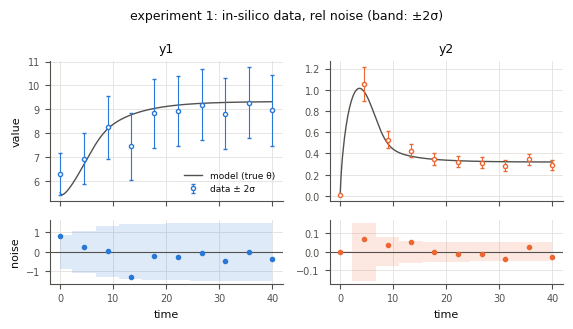

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed3\data_plots\experiment_1.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed3\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


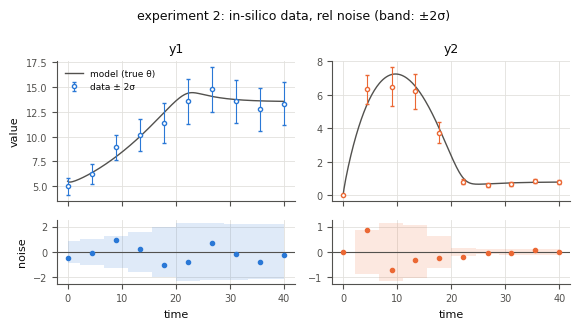

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed3\data_plots\experiment_2.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed3\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


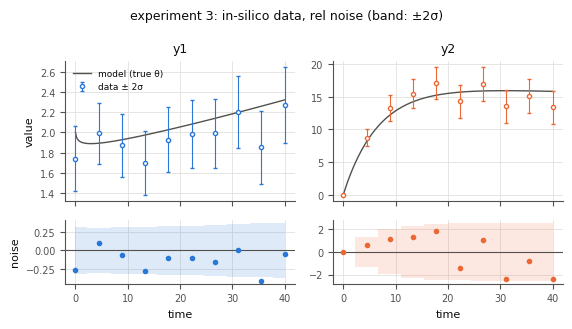

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed3\data_plots\experiment_3.png
[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.92e+01, cond(M)≈7.96e+03, λ_min(M)≈3.85e+01; OK


CI: [0.02275267 0.03363862 0.10140411 0.0224401 ]
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed4\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


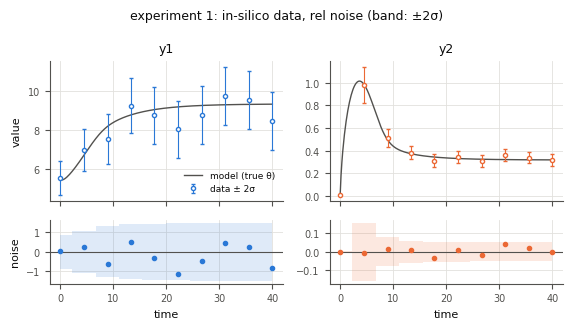

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed4\data_plots\experiment_1.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed4\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


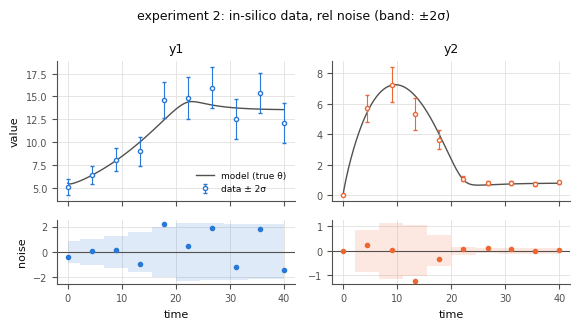

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed4\data_plots\experiment_2.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed4\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


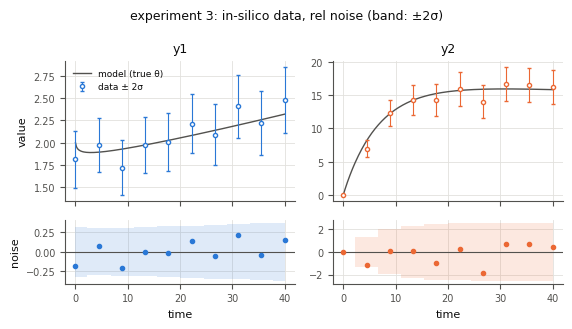

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\rel_0.08_seed4\data_plots\experiment_3.png
[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.82e+01, cond(M)≈7.78e+03, λ_min(M)≈4.03e+01; OK


CI: [0.02156173 0.03487221 0.09739545 0.02125758]


,mu_max,Ks,Yxs,m,CI mu_max [%],CI Ks [%],CI Yxs [%],CI m [%],mean |error| [%],t-tests passed,D2 (< 9.49 = truth inside)
seed 0,0.2285,0.2925,0.7883,0.0681,8.1,11.9,10.8,26.7,15.1,4.0,6.88
seed 1,0.2526,0.2468,0.8781,0.0926,9.5,13.6,12.2,25.5,1.4,4.0,2.28
seed 2,0.2636,0.2341,0.9349,0.1041,10.0,14.0,12.6,25.0,8.4,4.0,2.99
seed 3,0.2465,0.2519,0.8470,0.0869,9.2,13.4,12.0,25.8,2.3,4.0,4.36
seed 4,0.2439,0.2714,0.8412,0.0834,8.8,12.8,11.6,25.5,5.7,4.0,4.00


In [36]:
draws = {f'seed {seed}': fit_row(*make_data(f'rel_0.08_seed{seed}', 'rel', 0.08, seed=seed)) for seed in range(5)}
draws_table = pd.DataFrame(draws).T
draws_table

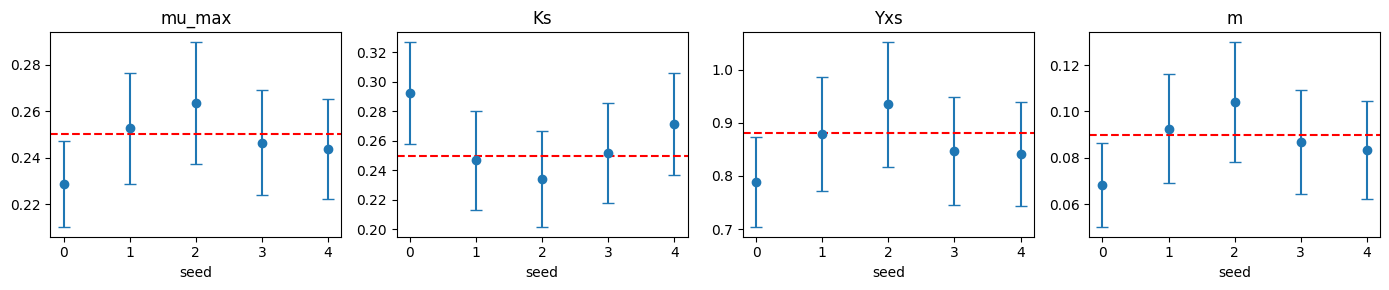

In [37]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3))
for k, name in enumerate(NAMES):
    est = draws_table[name].astype(float)
    ax[k].errorbar(range(5), est, yerr=est * draws_table[f'CI {name} [%]'].astype(float) / 100, fmt='o', capsize=4)
    ax[k].axhline(theta_true[k], color='r', ls='--')
    ax[k].set(title=name, xlabel='seed', xticks=range(5))
plt.tight_layout(); plt.show()

**What to look for:** the estimates jump from draw to draw by about the length of the bars, and
the red line (truth) is crossed by most bars. Seed 0, the data of Parts 4–7, is one of the less lucky
draws: its bars just miss, while its joint $D^2$ is still inside the limit. One data set is one draw.
Judge a method by many draws, as in the next section.

### 8.3 Error type and objective together

Part 6.3 compared objectives on one data set. To compare them fairly we fit **five draws** of relative
and of absolute data with all four objectives, and average the error against the truth.

[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.45e+01, cond(M)≈7.15e+03, λ_min(M)≈4.00e+01; OK


CI: [0.01851409 0.03481761 0.08541448 0.01814945]


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.45e+01, cond(M)≈7.15e+03, λ_min(M)≈4.00e+01; OK


... (64 outputs left out)

active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈4.19e+01, cond(M)≈1.75e+03, λ_min(M)≈2.62e+01; OK


CI: [0.01568436 0.12314411 0.06713995 0.01400161]


[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed1\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.5
   - y2         | measurable      | std.dev = 0.5


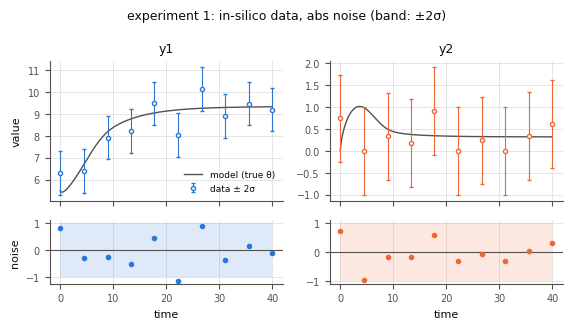

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed1\data_plots\experiment_1.png


[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed1\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.5
   - y2         | measurable      | std.dev = 0.5


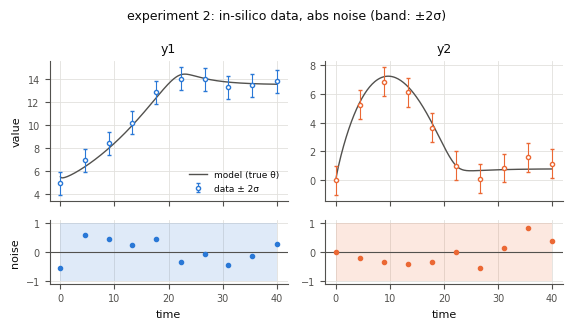

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed1\data_plots\experiment_2.png


[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed1\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.5
   - y2         | measurable      | std.dev = 0.5


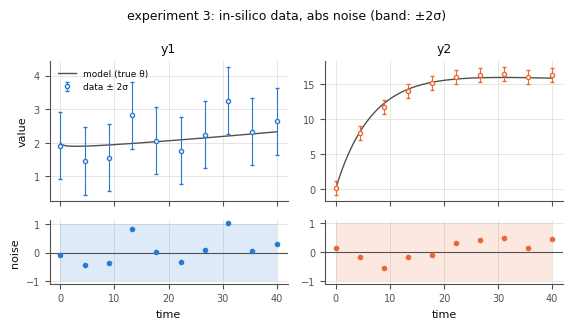

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed1\data_plots\experiment_3.png
[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈6.27e+01, cond(M)≈3.93e+03, λ_min(M)≈1.96e+01; OK


CI: [0.02409765 0.09040694 0.10817541 0.02288732]


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈6.27e+01, cond(M)≈3.93e+03, λ_min(M)≈1.96e+01; OK


... (3 outputs left out)

CI: [0.02409765 0.09040694 0.10817541 0.02288732]


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈9.51e+01, cond(M)≈9.04e+03, λ_min(M)≈1.02e+01; OK


CI: [0.02909831 0.07758842 0.12108011 0.02788561]
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed2\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.5
   - y2         | measurable      | std.dev = 0.5


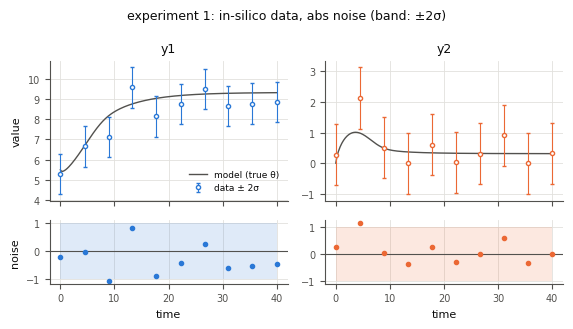

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed2\data_plots\experiment_1.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed2\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.5
   - y2         | measurable      | std.dev = 0.5


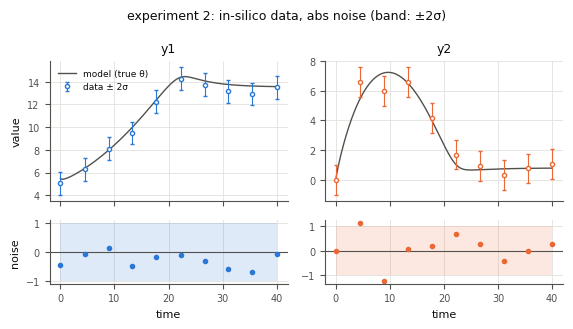

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed2\data_plots\experiment_2.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed2\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.5
   - y2         | measurable      | std.dev = 0.5


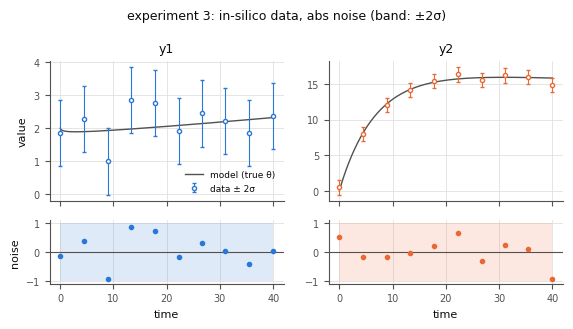

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed2\data_plots\experiment_3.png
[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈5.37e+01, cond(M)≈2.88e+03, λ_min(M)≈2.86e+01; OK


CI: [0.02624051 0.10612273 0.11729611 0.02513106]


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈5.37e+01, cond(M)≈2.88e+03, λ_min(M)≈2.86e+01; OK


... (3 outputs left out)

CI: [0.02624051 0.10612273 0.11729611 0.02513106]


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.05e+01, cond(M)≈6.48e+03, λ_min(M)≈1.62e+01; OK


CI: [0.02569854 0.09307416 0.11794502 0.02461136]
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed3\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.5
   - y2         | measurable      | std.dev = 0.5


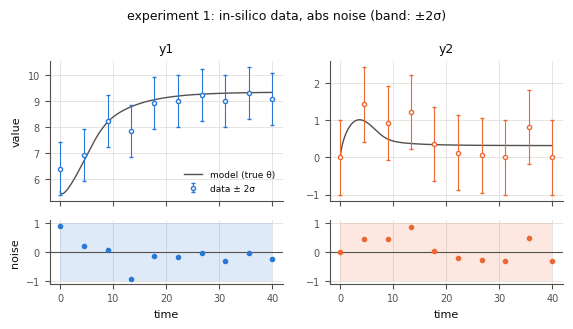

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed3\data_plots\experiment_1.png


[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed3\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.5
   - y2         | measurable      | std.dev = 0.5


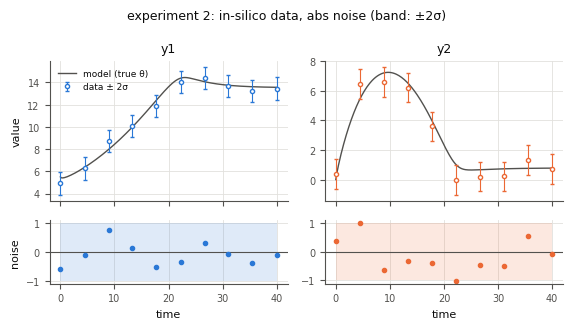

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed3\data_plots\experiment_2.png


[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed3\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.5
   - y2         | measurable      | std.dev = 0.5


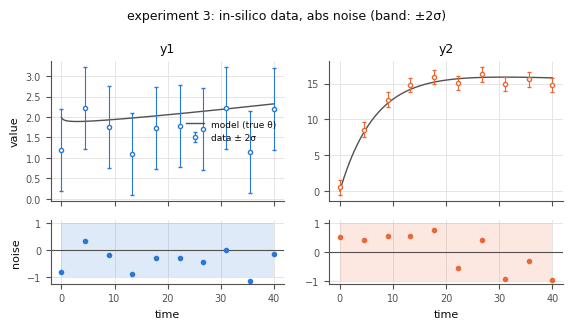

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed3\data_plots\experiment_3.png
[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈5.71e+01, cond(M)≈3.26e+03, λ_min(M)≈2.36e+01; OK


CI: [0.02440897 0.09585816 0.10929159 0.02322413]


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈5.71e+01, cond(M)≈3.26e+03, λ_min(M)≈2.36e+01; OK


... (3 outputs left out)

CI: [0.02440897 0.09585816 0.10929159 0.02322413]


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.32e+01, cond(M)≈6.92e+03, λ_min(M)≈9.02e+00; OK


CI: [0.02162618 0.08283352 0.09120591 0.02022846]
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed4\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.5
   - y2         | measurable      | std.dev = 0.5


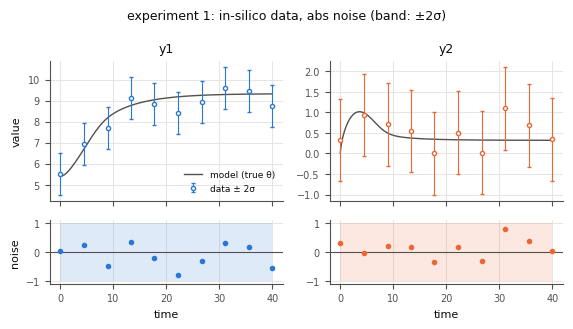

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed4\data_plots\experiment_1.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed4\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.5
   - y2         | measurable      | std.dev = 0.5


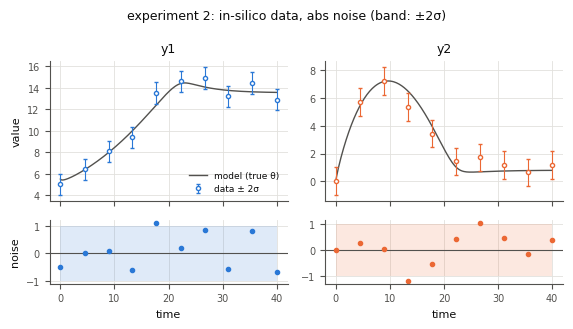

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed4\data_plots\experiment_2.png
[✓] In-silico data saved to: tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed4\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.5
   - y2         | measurable      | std.dev = 0.5


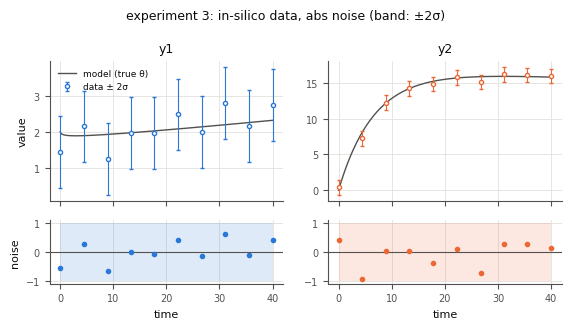

[INFO] Data preview       : tests\tutorials\01_estimation_and_uncertainty\error_study\abs_0.5_seed4\data_plots\experiment_3.png
[INFO] Reading from data.xlsx


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈5.63e+01, cond(M)≈3.17e+03, λ_min(M)≈2.62e+01; OK


CI: [0.02546565 0.09763415 0.11594095 0.02436748]


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈5.63e+01, cond(M)≈3.17e+03, λ_min(M)≈2.62e+01; OK


... (4 outputs left out)

active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈4.27e+01, cond(M)≈1.83e+03, λ_min(M)≈2.92e+01; OK


CI: [0.01819273 0.11761563 0.07940691 0.0167314 ]


objective,Chi,LS,MLE,WLS
data,,,,
abs 0.5,21.36,6.86,6.86,6.86
rel 0.08,7.48,12.34,6.58,6.58


In [38]:
rows = []
for errt, unc in [('rel', 0.08), ('abs', 0.5)]:
    for seed in range(5):
        system_s, data_s = make_data(f'{errt}_{unc}_seed{seed}', errt, unc, seed=seed)
        for ob in ['WLS', 'MLE', 'LS', 'Chi']:
            rows.append({'data': f'{errt} {unc}', 'seed': seed, 'objective': ob, **fit_row(system_s, data_s, ob)})
combo = pd.DataFrame(rows)
combo_mean = combo.pivot_table(index='data', columns='objective', values='mean |error| [%]')
combo_mean

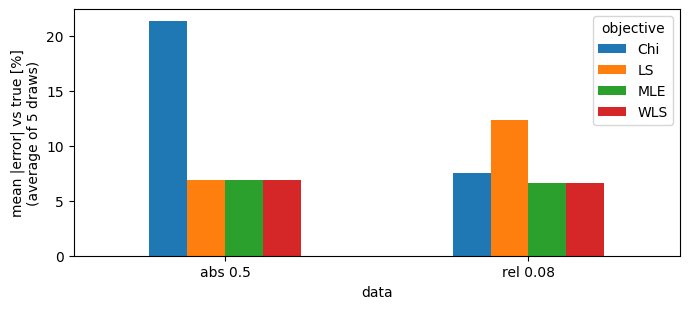

[INFO] Reading from data.xlsx


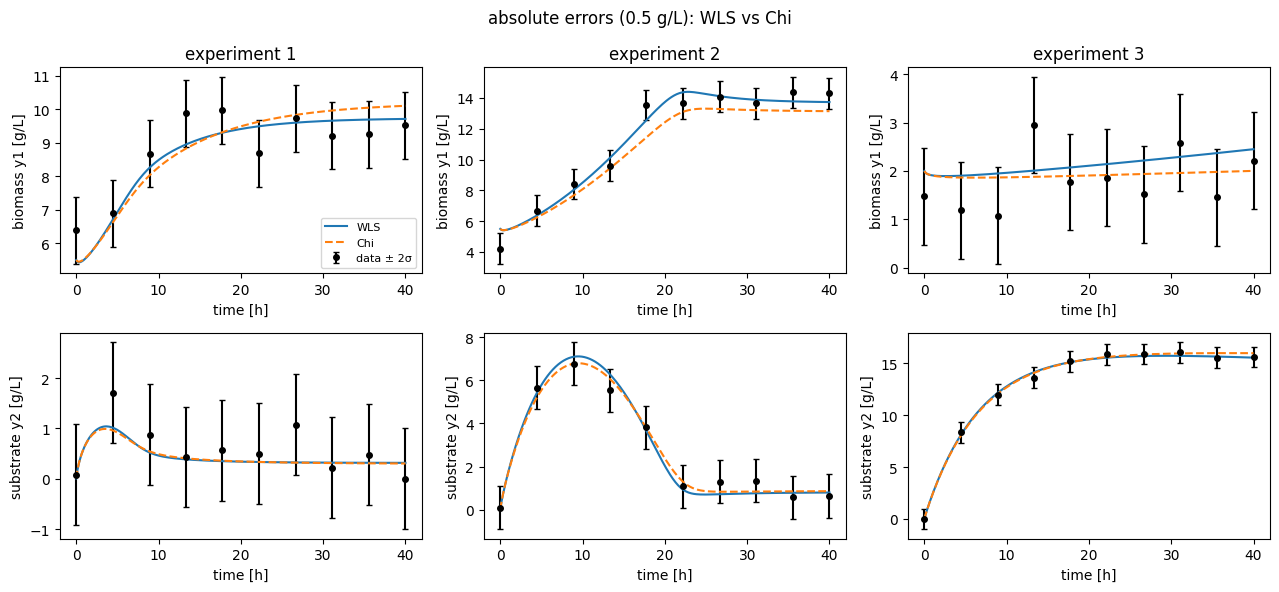

In [39]:
combo_mean.plot.bar(figsize=(7, 3.2), rot=0)
plt.ylabel('mean |error| vs true [%]\n(average of 5 draws)'); plt.tight_layout(); plt.show()

system_a, data_a = make_data('abs_0.5_seed0', 'abs', 0.5)
fit_wls_a = parmest(system_a, copy.deepcopy(models_start), iden_opt, data=data_a)['MI']['scpr']
fit_chi_a = parmest(system_a, copy.deepcopy(models_start), dict(iden_opt, ob='Chi'), data=data_a)['MI']['scpr']
plot_fit({'WLS': fit_wls_a, 'Chi': fit_chi_a}, dataset=data_a, title="absolute errors (0.5 g/L): WLS vs Chi")

**What to look for:**

- **MLE = WLS.** With σ known (from `MES_E`), MLE adds only the constant
  $\tfrac12\sum\ln(2\pi\sigma_i^2)$ to WLS/2, so both have the same minimum and the same numbers
  in the table. (MIDDoE minimises MLE without the constant; with the constant, which is large and
  negative here, the optimiser's relative stopping test would end a few digits early.) The two
  objectives differ only when σ is estimated as well, which MIDDoE v1 does not do.
- **Relative errors:** WLS and Chi do about equally well; both weight each point by its relative
  precision. LS gives too little weight to the small substrate values.
- **Absolute errors:** every point has the same σ, so WLS, MLE and LS are the same fit (identical
  numbers). **Chi is clearly worse** (about 3 times the error). It weights each point by $1/y_i^2$, as if
  the error were relative. All points have the same σ = 0.5 g/L, yet the substrate values near
  0.3 g/L, which are mostly noise, get about 1000 times the weight of the biomass values near 10 g/L.
- In the plot the WLS and Chi curves look alike, while their parameters differ by 15–40 % ($m$ most). With
  correlated parameters, different parameter sets give almost the same curves. A fit that looks good
  does not mean the parameters are right; compare estimates, not only curves.
- **Why Chi has a floor.** Some of these substrate values were measured as 0: the noise is larger
  than the value, and negative draws are clipped. Plain relative LS divides by them and gives one
  point a weight of about $10^{16}$, so the fit only tries to hit that point. **[MIDDoE extra]**
  MIDDoE floors $\lvert y_i\rvert$ at the point's σ, so such a point gets the weight $1/\sigma_i^2$, as in
  WLS. The floor prevents that breakdown; it does not turn Chi into the right objective for absolute
  errors.
- **Rule:** the objective must match the error type. WLS with the right σ is always safe. LS only
  if all points have the same σ. Chi only for relative errors.

### 8.4 Declaring the wrong σ

With real data **you** write σ into `MES_E`. What if it is wrong? We take the data of Parts 4–7 and
declare σ half as large and twice as large as the truth. Only the `MES_E` columns change.

In [40]:
assumed = {}
for factor in [0.5, 1, 2]:
    data_f = {name: sheet.copy() for name, sheet in data.items()}
    for sheet in data_f.values():
        for y in ['y1', 'y2']:
            sheet[f'MES_E:{y}'] = sheet[f'MES_E:{y}'] * factor        # the sigma we *declare*
    out = uncert(parmest(system, copy.deepcopy(models_start), iden_opt, data=data_f),
                 system, models_start, iden_opt, case='check', data=data_f)
    r = out['results']['MI']
    assumed[f'sigma x {factor}'] = {**dict(zip(NAMES, np.round(r['estimations'], 4))),
                                    **{f'CI {n}': round(c, 4) for n, c in zip(NAMES, r['CI'])},
                                    'WLS / (N - 4)': round(r['WLS'] / (out['obs'] - 4), 2)}
assumed_table = pd.DataFrame(assumed).T
assumed_table

active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.45e+01, cond(M)≈7.15e+03, λ_min(M)≈1.60e+02; OK


CI: [0.00925704 0.0174088  0.04270724 0.00907473]


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.45e+01, cond(M)≈7.15e+03, λ_min(M)≈4.00e+01; OK


CI: [0.01851409 0.03481761 0.08541448 0.01814945]


active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.45e+01, cond(M)≈7.15e+03, λ_min(M)≈9.99e+00; OK


CI: [0.03702817 0.06963521 0.17082895 0.0362989 ]


,mu_max,Ks,Yxs,m,CI mu_max,CI Ks,CI Yxs,CI m,WLS / (N - 4)
sigma x 0.5,0.2285,0.2925,0.7883,0.0681,0.0093,0.0174,0.0427,0.0091,4.34
sigma x 1,0.2285,0.2925,0.7883,0.0681,0.0185,0.0348,0.0854,0.0181,1.08
sigma x 2,0.2285,0.2925,0.7883,0.0681,0.0370,0.0696,0.1708,0.0363,0.27


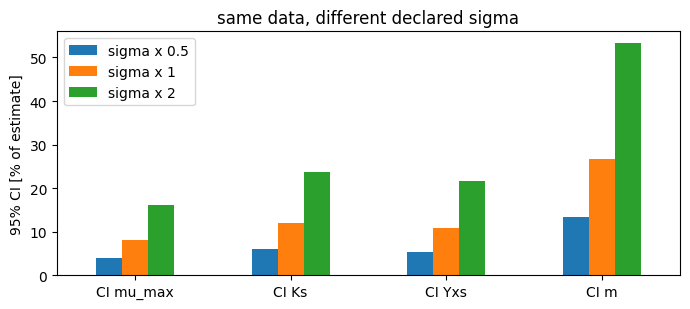

In [41]:
assumed_table[[f'CI {n}' for n in NAMES]].div(res['estimations'], axis=1).mul(100).T.plot.bar(figsize=(7, 3.2), rot=0)
plt.ylabel('95% CI [% of estimate]'); plt.title('same data, different declared sigma'); plt.tight_layout(); plt.show()

**What to look for:**

- **The estimates do not change.** Scaling every σ by the same factor does not change where the WLS
  minimum is.
- **The intervals scale with the declared σ.** Declare σ too small and MIDDoE reports a precision you
  do not have: parameters "pass" t-tests they should fail. Declare it too large and you throw away
  precision.
- **The fit tells you.** $WLS/(N-p)$ should be about 1. Here it is 4.3, 1.1 and 0.27, that is
  $1/\text{factor}^2$. A value far from 1 means σ is wrong (or the model is: check the residual
  plot of Part 6 for trends first).

**How to choose `errt` and `unc` for your own study.**

- Use `'rel'` when the instrument's precision is quoted in % (many analysers, HPLC). Use `'abs'` when
  it is quoted in units (balances, pressure and temperature sensors).
- Set `unc` from replicate measurements or the instrument datasheet, not from the fit.
- With `'rel'`, set `sigma_floor` to the detection limit, so that values near zero do not get an
  unrealistic weight.
- After the fit, check $WLS/(N-p) \approx 1$ and the residual plot.

---
## Part 9. Reporting

A MIDDoE study proceeds in **rounds**: after each new experiment the parameters are estimated again.
Reporting has three levels:

| Level | Function | Produces |
|---|---|---|
| each round | `save_rounds(round, result, label, round_data, models, iden_opt, obs, system, data=...)` | stores the round in `round_data`, prints the t-test and P, returns $t_{ref}$; draws the fit with weighted residuals and a parity plot (`f_plt` → folder `modelling/`) and the 95 % confidence regions (`c_plt` → `confidence/`) |
| saving | `save_to_jac(round_data, 'iden')`, `load_from_jac()` | the whole study in `iden_results.jac`, reloaded later without rerunning anything |
| final report | `run_postprocessing(round_data, ['MI'], [1, 2, 3], ...)` | folder `post_processing/`: plots across rounds, one Excel report per round, a text summary |

Here we replay the study as three rounds: round 1 uses experiment 1, round 2 adds experiment 2, round 3
adds experiment 3. The models are updated after each round (`case=None`), as in a real sequential study.
**[MIDDoE extra]** `data=` tells `save_rounds` to plot only the experiments of that round.

In [42]:
round_data = {}
models_rounds = copy.deepcopy(models_start)
models_rounds['theta_names'] = {'MI': NAMES}   # optional: parameter names on the plots (default theta_1 ...)
for round_number, experiments in [(1, ['1']), (2, ['1', '2']), (3, ['1', '2', '3'])]:
    data_round = {sheet: data[sheet] for sheet in experiments}
    fit_round = parmest(system, models_rounds, iden_opt, data=data_round)
    unc_round = uncert(fit_round, system, models_rounds, iden_opt, data=data_round)       # updates models_rounds
    save_rounds(round_number,          # round number (1, 2, ...)
                unc_round['results'],  # the uncert results of this round
                'classic',             # design type of the round: 'classic'/'preliminary', 'MBDOE_PP', 'MBDOE_MD'
                                       #   (any label containing PP or MD works); shades the round in the final plots
                round_data,            # dict filled in place, one entry per round
                models_rounds,         # models after uncert (current estimates)
                iden_opt,              # its c_plt / f_plt / plt_s switch the plots
                unc_round['obs'],      # number of measured points
                system,
                data=data_round)       # optional: plot only these experiments (default: data.xlsx)
                # with estimability analysis also: ranking=, k_optimal_value=, rCC_values=, J_k_values=

active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈4.19e+01, cond(M)≈1.75e+03, λ_min(M)≈1.18e+01; OK


CI: [0.05854289 0.07695406 0.28827311 0.04858103]


reference t value for model MI and round 1: 2.119905299221011
estimated t values for model MI and round 1: [9.86159399 6.80554094 7.48352559 4.59793169]
P-value for model MI and round 1: 100.0



active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈7.58e+01, cond(M)≈5.75e+03, λ_min(M)≈3.85e+01; OK


... (2 outputs left out)

active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈8.45e+01, cond(M)≈7.14e+03, λ_min(M)≈4.00e+01; OK


CI: [0.01850995 0.03481871 0.0853961  0.01814529]


reference t value for model MI and round 3: 2.003240718847872
estimated t values for model MI and round 3: [24.73222713 16.82864139 18.48985234  7.51243466]
P-value for model MI and round 3: 100.0



`save_rounds` arguments:

- the round number;
- the `uncert` results;
- the design type of the round (`'classic'`/`'preliminary'`, `'MBDOE_PP'`, `'MBDOE_MD'`), used to shade the rounds in the final plots;
- the round dictionary, filled in place;
- `models` and `iden_opt` (the plot flags);
- the number of points and `system`;
- optionally `data`.

With estimability analysis (a later tutorial) it also takes `ranking`, `k_optimal_value`,
`rCC_values` and `J_k_values`.

Round 3's fit to experiment 3: the data with ±2σ error bars, the model with the 95 % band of its
prediction due to the parameter uncertainty, and under each output the weighted residuals
$(y-\hat y)/\sigma$, which should stay within ±2 without trends. The caption gives
$\sum[(y-\hat y)/\sigma]^2/(N-p)$ with its 95 % range for a correct model and σ (Part 6).
Then the parity plot (measured against model) and the confidence regions: on the diagonal each
parameter's density with its 95 % CI, below it the 95 % joint ellipse of each pair, above it the
correlation coefficient.

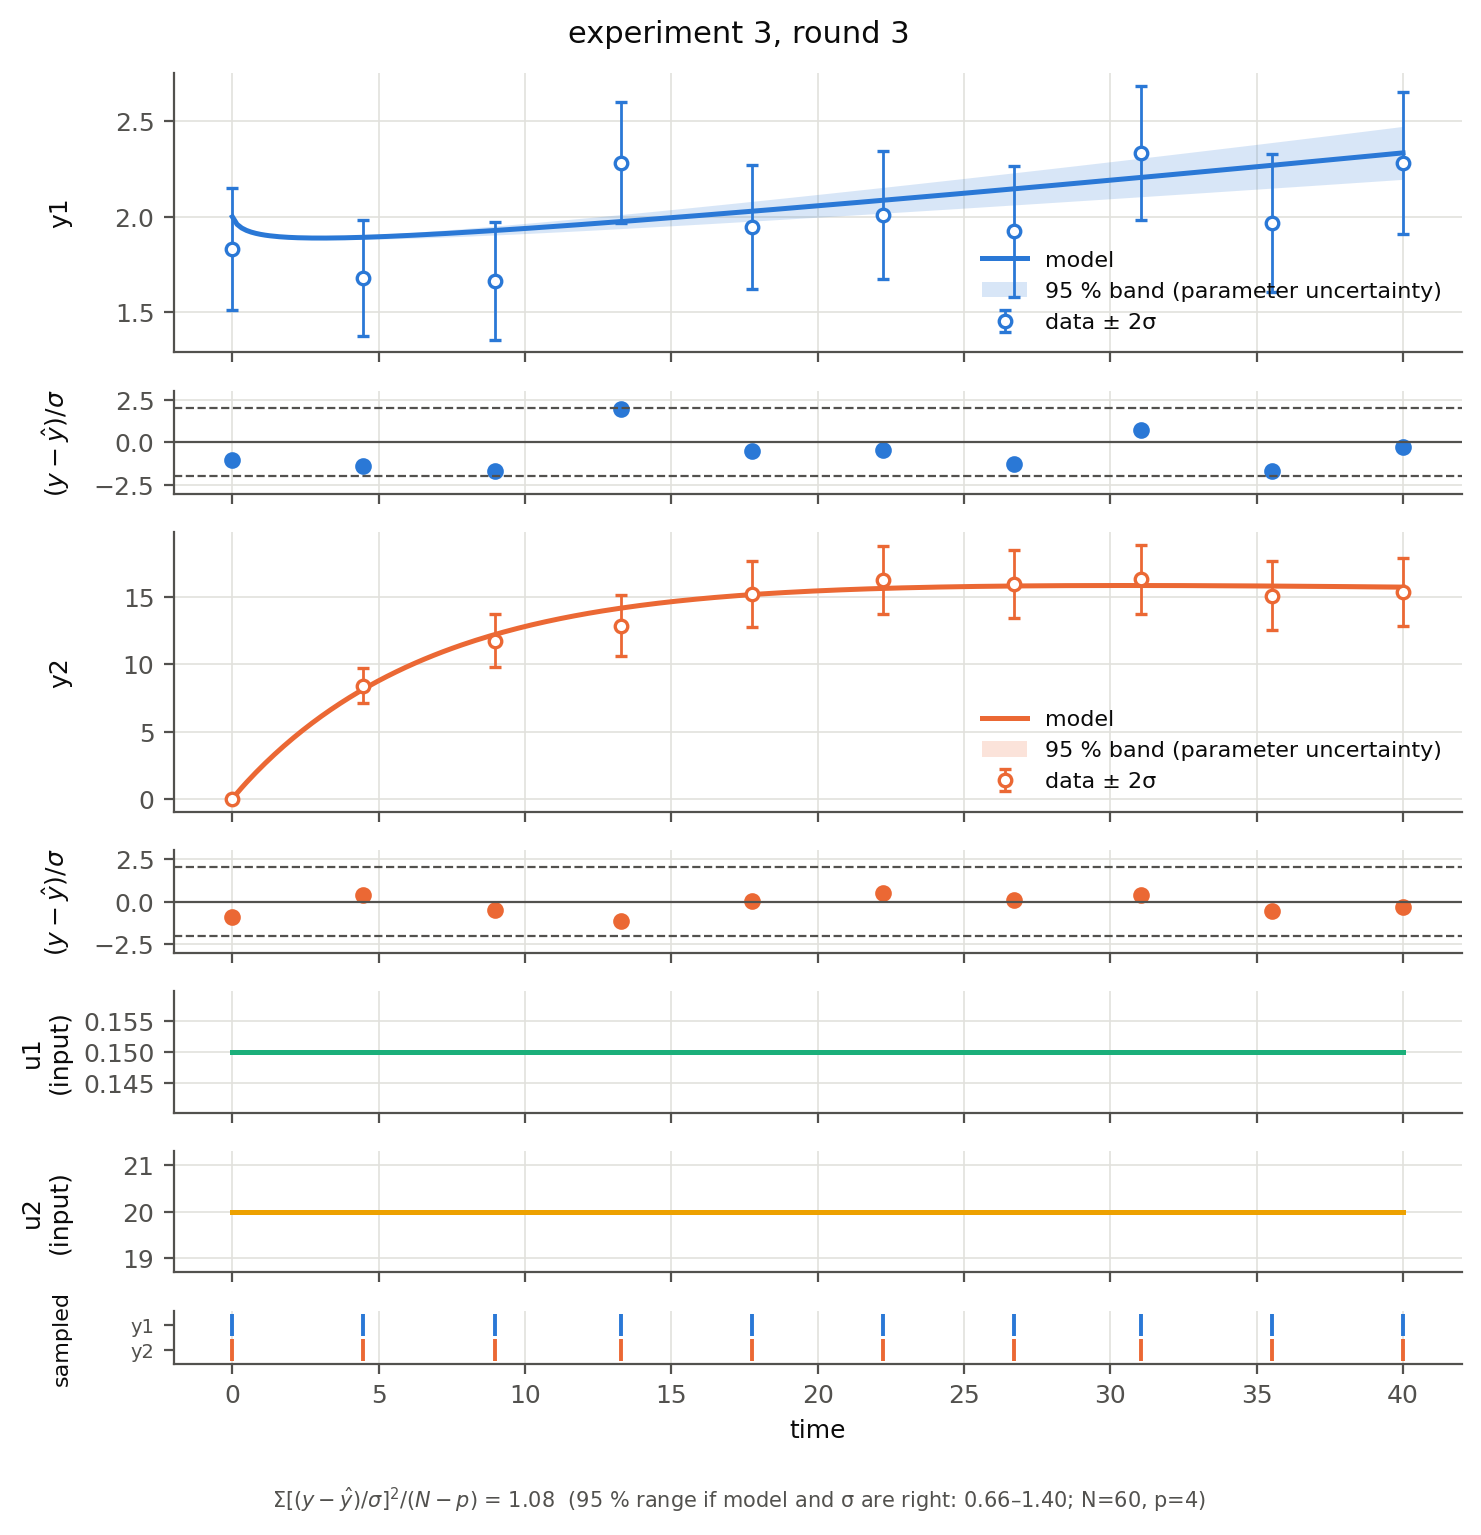

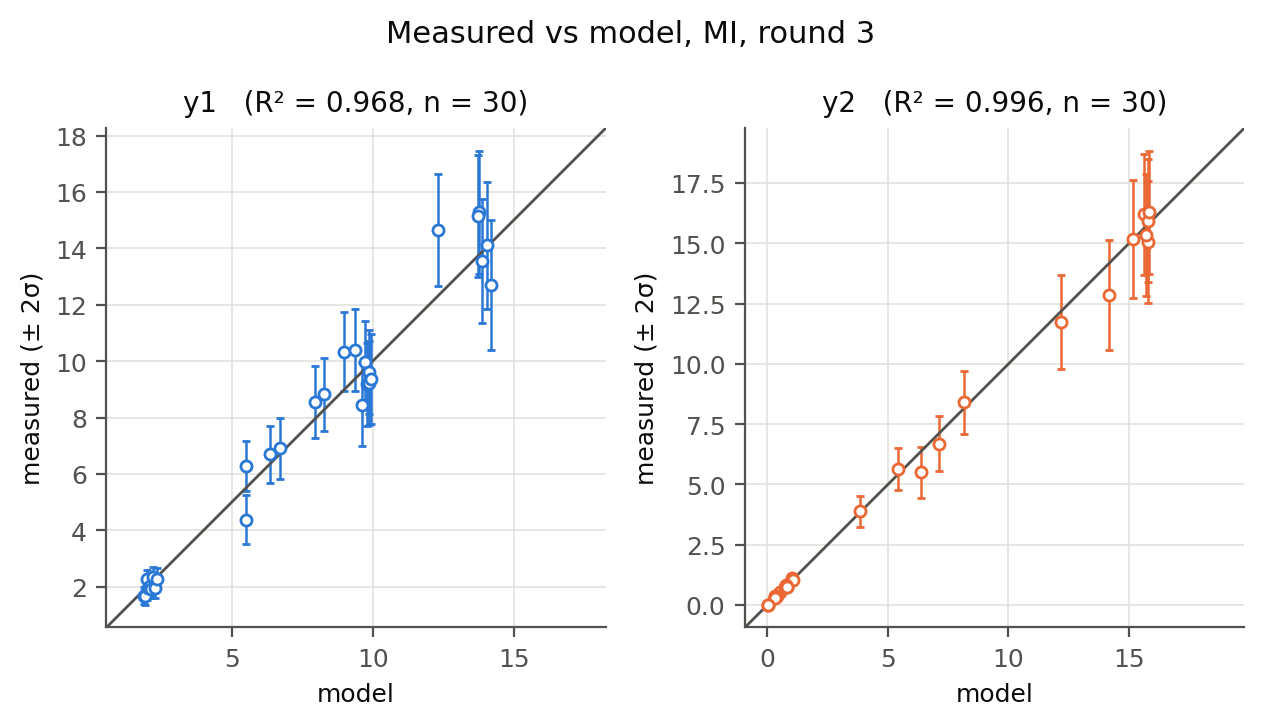

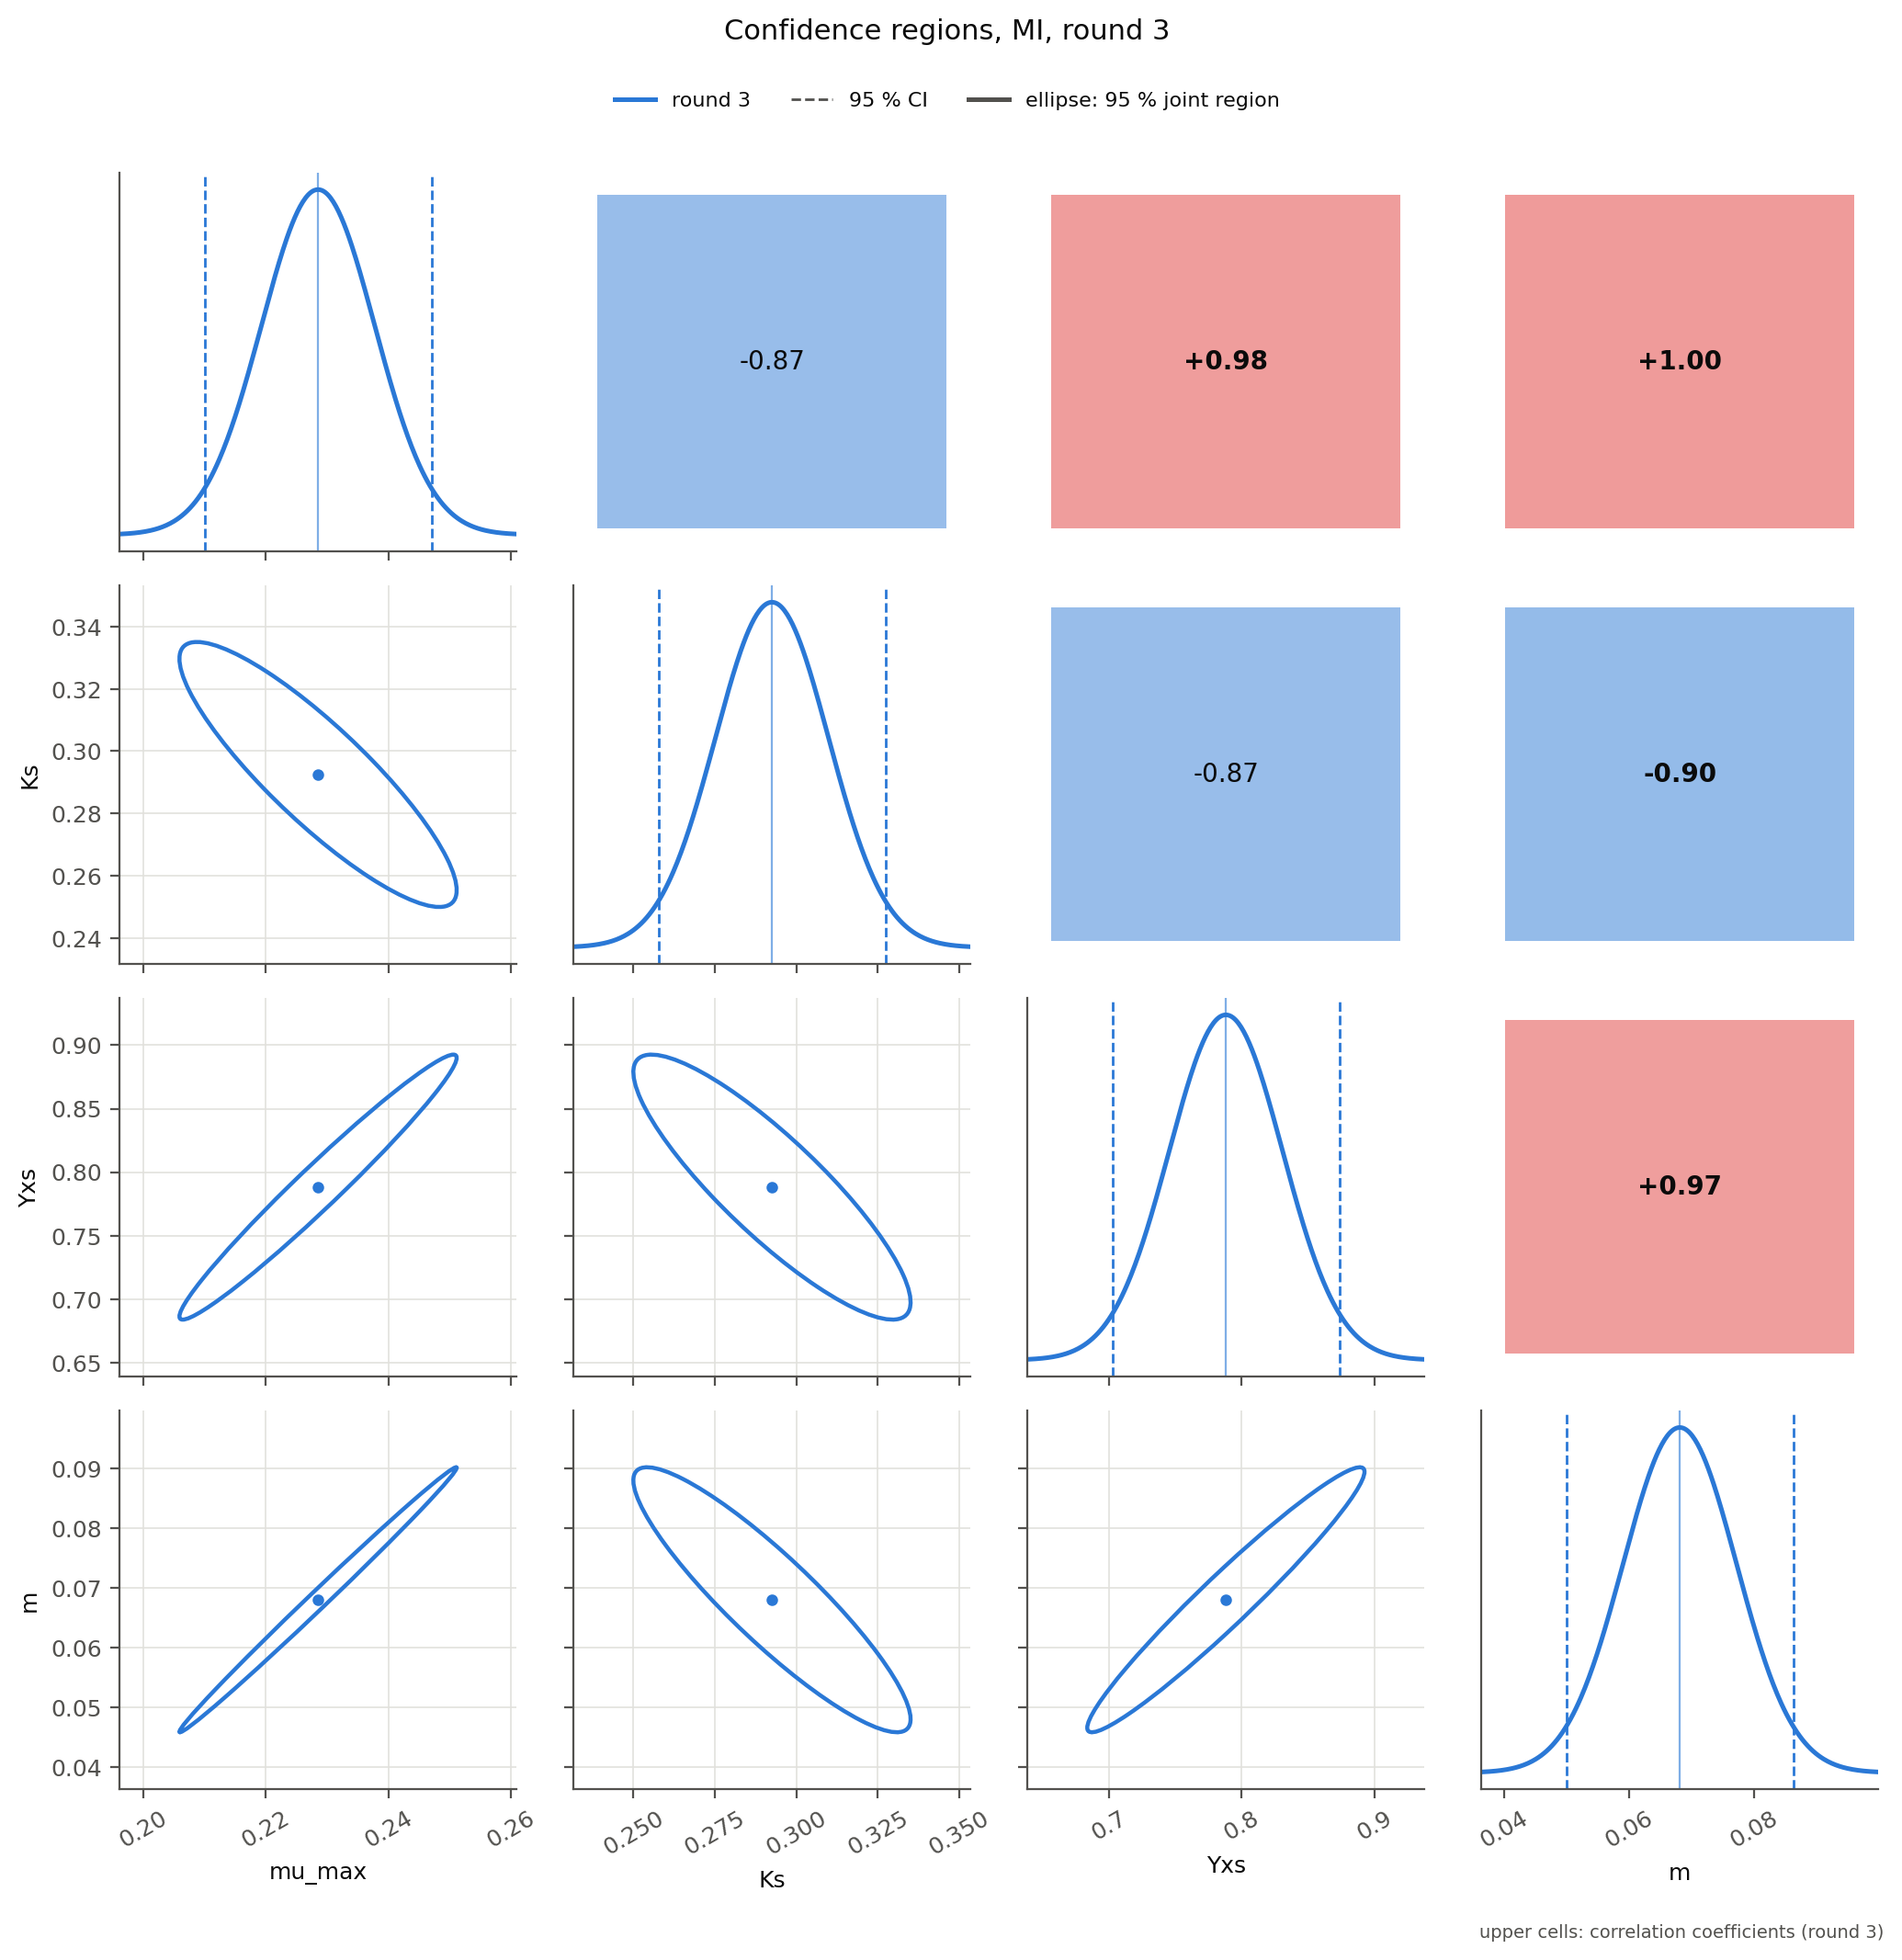

In [43]:
display(Image('modelling/3_round_3.png', width=550))
display(Image('modelling/3_parity_MI.png', width=500))
display(Image('confidence/3_th_round_MI.png', width=650))

Narrow, tilted ellipses and correlation coefficients near ±1 are the strong correlations of Part 7.

**Saving and reloading.** `save_to_jac` writes the whole `round_data` to `iden_results.jac` (a pickle
file). `load_from_jac()` reads it back as `{'iden': ..., 'sensa': ...}`. `'sensa'` holds the
sensitivity results of a later tutorial and is `None` here.

In [44]:
save_to_jac(round_data, 'iden')     # purpose: 'iden' = identification rounds (this tutorial),
                                    #   'sensa' = Sobol sensitivity results (later tutorial)
loaded = load_from_jac()            # reads iden_results.jac / sensa_results.jac from the working folder
print('rounds in the file:', list(loaded['iden']))

[INFO] Results saved to: tests\tutorials\01_estimation_and_uncertainty\iden_results.jac
Loaded: iden_results.jac
File not found: sensa_results.jac
rounds in the file: ['Round 1', 'Round 2', 'Round 3']


**Final report.** `run_postprocessing(round_data, solvers, selected_rounds, ...)` has one switch
per output:

| Option | Output in `post_processing/` |
|---|---|
| `plot_global_p_and_t` | `t_values_round_k.png`: t of every parameter against $t_{ref}$, per round; with several models also `p_values_round_k.png` (P of every model) |
| `plot_confidence_spaces` | `MI_confidence_space.png` (95 % regions of all rounds overlaid), `MI_parameter_estimates.png` (estimate ± 95 % CI per round, true values with `true_theta`), `MI_parameter_std_devs.png` (sd in % of the estimate), `MI_ellipsoid_volume.png` (volume of the 95 % joint region) |
| `plot_p_and_t_tests` | `MI_pt_tests.png`: t-values against $t_{ref}$ over the rounds (and P with several models), rounds shaded by design type |
| `export_excel_reports` | `MI_report_k.xlsx` (per experiment: data, σ, model at the sampling times, residuals, model curves, inputs; sheet `_summary`: estimates, CI, t-test, fit statistics) and `MI_report_summary.txt` |
| `plot_estimability` | `rCC` vs $k$ plots; needs estimability analysis, so it is off here |

`true_theta` (optional) draws the true parameter values on the estimate plot; only known in silico.
It also shows every plot in the notebook.

P-value plots skipped: only one model, so its probability is always 100 %.


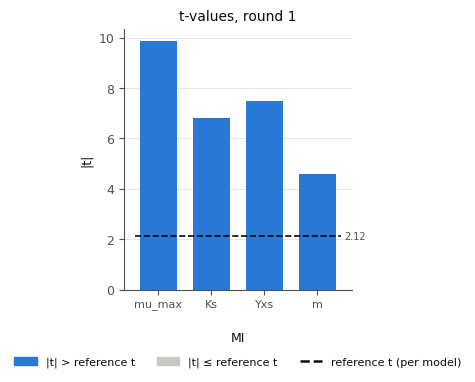

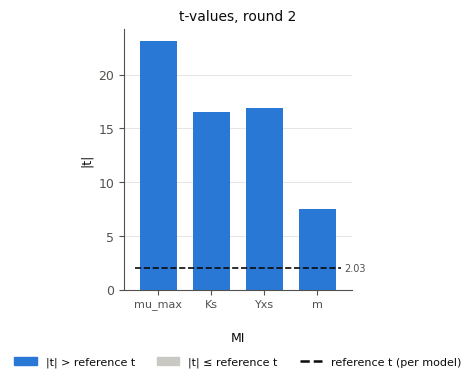

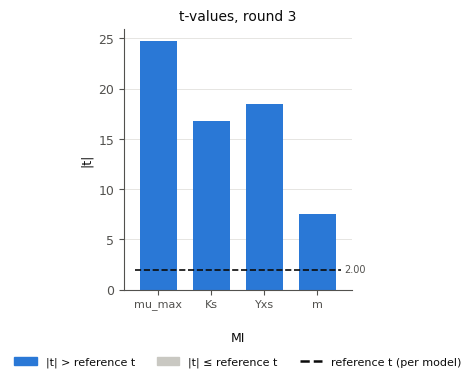

Post-processing model: MI


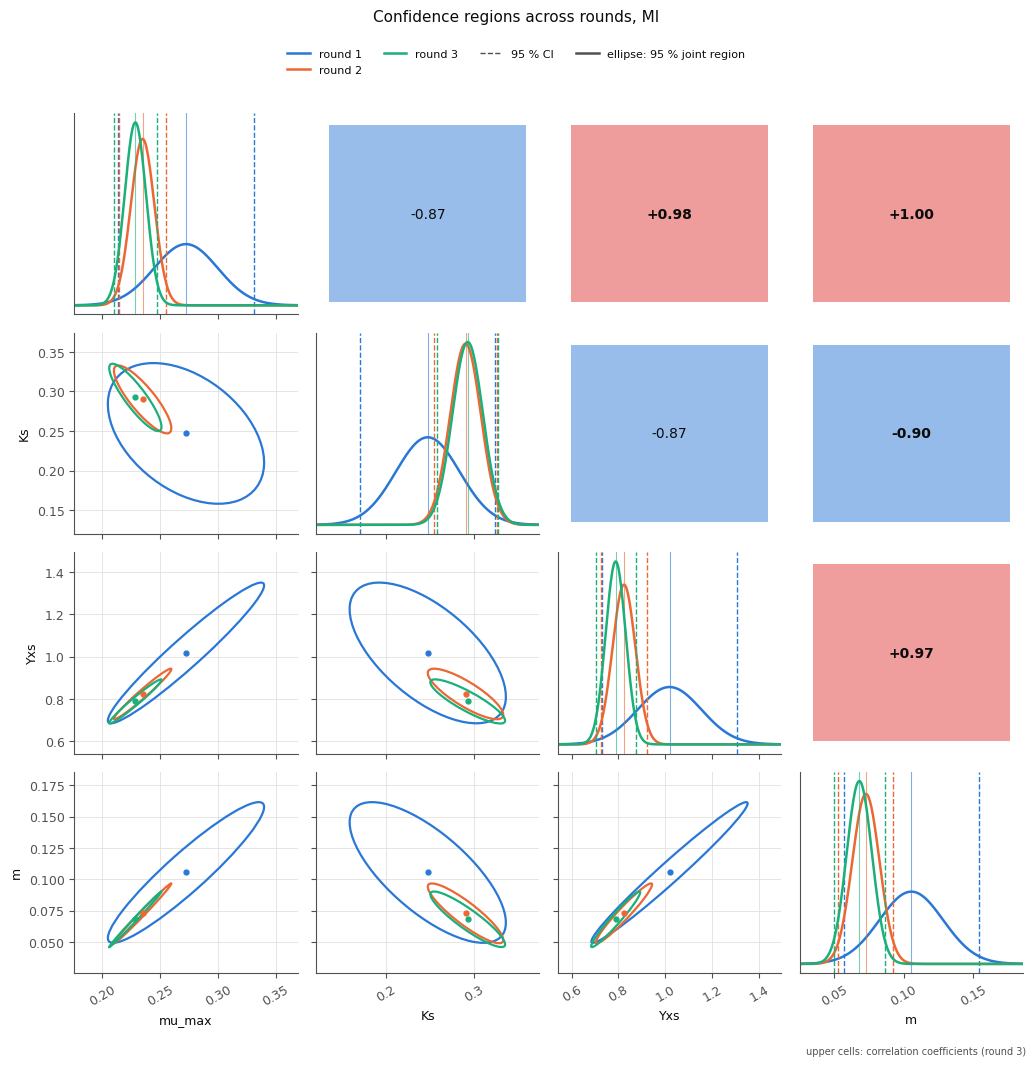

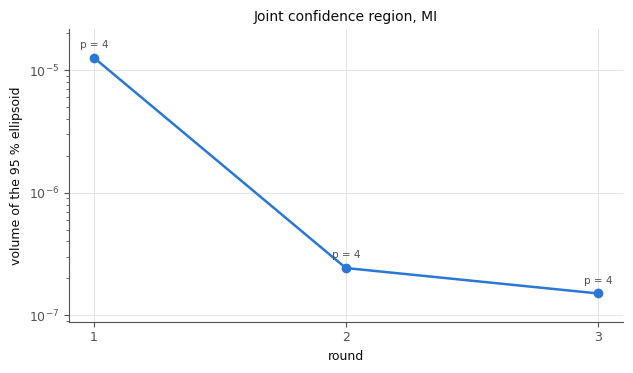

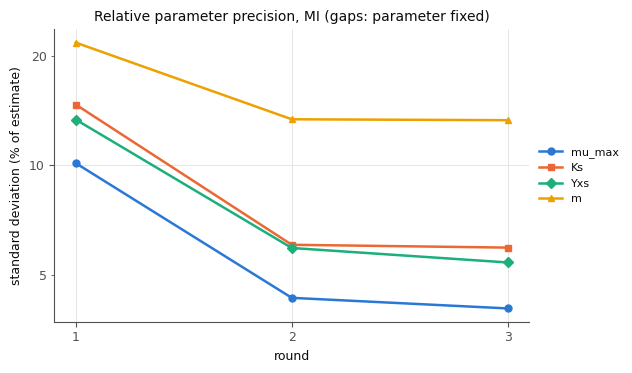

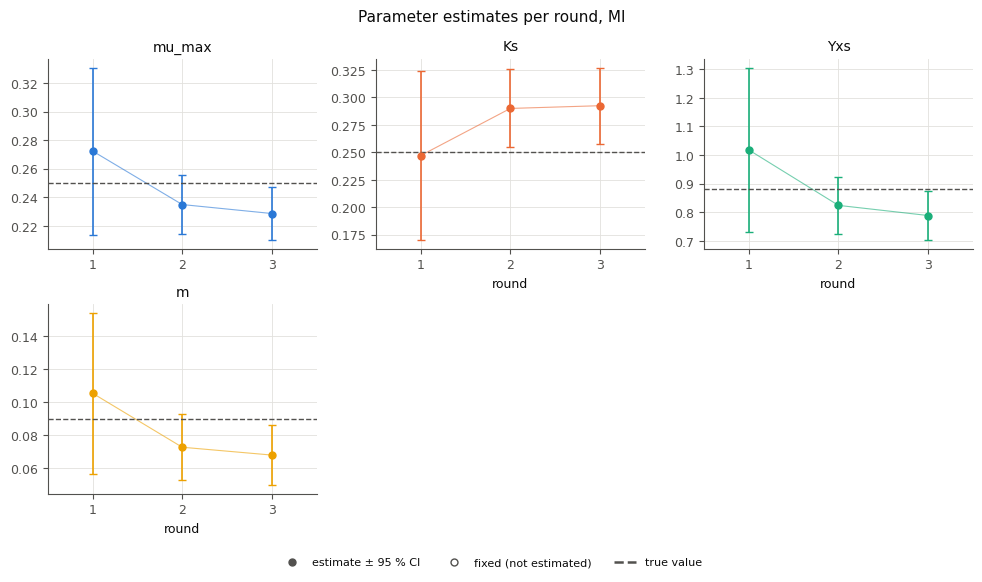

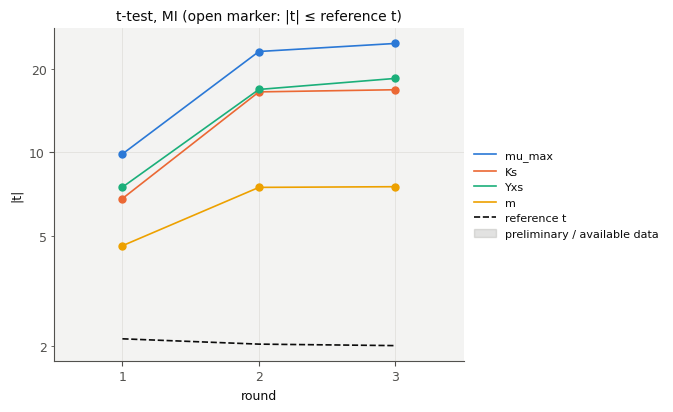

INFO:middoe.iden_utils:Reporter wrote Round 1 to 'tests\tutorials\01_estimation_and_uncertainty\post_processing\MI_report_1.xlsx'.


INFO:middoe.iden_utils:Reporter wrote Round 2 to 'tests\tutorials\01_estimation_and_uncertainty\post_processing\MI_report_2.xlsx'.


INFO:middoe.iden_utils:Reporter wrote Round 3 to 'tests\tutorials\01_estimation_and_uncertainty\post_processing\MI_report_3.xlsx'.


INFO:middoe.iden_utils:Summary written to 'tests\tutorials\01_estimation_and_uncertainty\post_processing\MI_report_summary.txt'.


Post-processing completed for: MI


In [45]:
run_postprocessing(round_data,       # the dict filled by save_rounds (or load_from_jac()['iden'])
                   ['MI'],           # models to report (names in can_m)
                   [1, 2, 3],        # rounds to report
                   plot_global_p_and_t=True,     # P of every model and t of every parameter, per round
                   plot_confidence_spaces=True,  # ellipses of all rounds, volume, std devs, estimates
                   plot_p_and_t_tests=True,      # P and t-values over the rounds
                   export_excel_reports=True,    # MI_report_k.xlsx per round + MI_report_summary.txt
                   plot_estimability=False,      # rCC vs k plots; needs estimability analysis (default True)
                   true_theta={'MI': theta_true},  # optional: true values (in silico only), dashed lines
                   show=True)                    # True (default) = also show every plot;
                                                 #   False = only save them (use in scripts)

How the study converged, read from the report files:

In [46]:
print(open('post_processing/MI_report_summary.txt', encoding='utf-8').read())
display(pd.read_excel('post_processing/MI_report_3.xlsx', sheet_name='1').head())
pd.read_excel('post_processing/MI_report_3.xlsx', sheet_name='_summary')

Round 3  (design: classic)

Model: MI
                   parameter      estimate estimated       sd  CI95 (±)  CI95 (% of estimate)         t    t_ref significant
                      mu_max      0.228526      True 0.009240  0.018510              8.099718 24.732227 2.003241        True
                          Ks      0.292502      True 0.017381  0.034819             11.903758 16.828641 2.003241        True
                         Yxs      0.788203      True 0.042629  0.085396             10.834271 18.489852 2.003241        True
                           m      0.068047      True 0.009058  0.018145             26.665666  7.512435 2.003241        True
                                                                                                                            
            N (measurements)            60                                                                                  
    p (estimated parameters)             4                                             

,MES_X:y1,MES_Y:y1,MES_E:y1 (sigma used),MOD:y1,RES:y1,WRES:y1,MES_X:y2,MES_Y:y2,MES_E:y2 (sigma used),MOD:y2,RES:y2,WRES:y2,SIM_t_model,SIM_y1,SIM_y2,INP_u1,INP_u2
0,0.00,6.276183,0.440000,5.500000,0.776183,1.764052,0.00,0.010115,0.000800,0.010000,0.000115,0.144044,0.00,5.500000,0.010000,0.05,30
1,4.48,6.902789,0.535093,6.716431,0.186357,0.348271,4.48,1.100059,0.078833,1.019127,0.080932,1.026630,0.16,5.446968,0.185418,0.05,30
2,8.96,8.820927,0.654433,8.266630,0.554296,0.846987,8.96,0.523690,0.039491,0.530197,-0.006508,-0.164787,0.32,5.435283,0.307913,0.05,30
3,13.28,10.330507,0.700806,8.985682,1.344825,1.918969,13.28,0.377833,0.029935,0.393194,-0.015361,-0.513131,0.48,5.441917,0.406329,0.05,30
4,17.76,10.388703,0.723067,9.381596,1.007107,1.392827,17.76,0.356207,0.027519,0.353337,0.002870,0.104276,0.64,5.459573,0.489740,0.05,30


,parameter,estimate,estimated,sd,CI95 (±),CI95 (% of estimate),t,t_ref,significant
0,mu_max,0.228526,1.0,0.009240,0.018510,8.099718,24.732227,2.003241,1.0
1,Ks,0.292502,1.0,0.017381,0.034819,11.903758,16.828641,2.003241,1.0
2,Yxs,0.788203,1.0,0.042629,0.085396,10.834271,18.489852,2.003241,1.0
3,m,0.068047,1.0,0.009058,0.018145,26.665666,7.512435,2.003241,1.0
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,N (measurements),60,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,p (estimated parameters),4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,sum((y - y_model)/sigma)^2,60.709216,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,ratio to N - p (expected ~1),1.084093,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,95 % range of the ratio,0.664 - 1.403,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In the Excel report, per output `MES_X`/`MES_Y` are the measurements, `MES_E` the σ used for each
point (from the data, or `unc` where missing), `MOD` the model at the sampling times, `RES` the residual
and `WRES` the weighted residual $(y-\hat y)/\sigma$; `SIM_*` is the model on the full time grid and
`INP_*` the inputs. Sheet `_summary` has the estimates, sd, 95 % CI, t against $t_{ref}$, and the fit
statistics. Use it to make your own figures.

---
## Summary

| Step | Call | You choose | Consequence |
|---|---|---|---|
| model | `model.py` with `solve_model(t, y0, tii, tvi, theta)` | equations; names that match `system` | |
| experiment | `system` | inputs, outputs, ranges, σ (`unc`) | |
| model setup | `models` | starting guess, bounds, free parameters | fixing a parameter at a wrong value biases the others |
| synthetic data | `expera(system, models, insilicos, {}, expr=k)` | `errt` (`'abs'`/`'rel'`), `unc`, `sigma_floor` | the noise level scales the CI; the error type decides which parameters are well determined |
| look at the data | `read_excel()`, plot `MES_X`/`MES_Y`/`MES_E` | | outliers, coverage of conditions, which points carry most weight |
| estimation | `parmest(system, models, iden_opt)` | `meth`, `ms`, `ob`, `tol` | methods differ in cost and robustness, not in the answer (one minimum); a loose `tol` can report success at a wrong point, so compare objective values; the objective must match the error type |
| check the fit | plot data vs model, weighted residuals | | residuals within ±2 without trends; $WLS/(N-p) \approx 1$, otherwise σ or the model is wrong |
| precision | `uncert(resultpr, system, models, iden_opt)` | `var-cov` (`'M'`, `'H'`, `'B'`), `nboot`, `sens_m`, `eps` | pair `'H'`/`'B'` with LS; the CI is only as honest as the declared σ; judge correlated parameters jointly |
| reporting | `save_rounds`, `save_to_jac`, `run_postprocessing` | plot and report switches | plots, Excel reports and a summary per round |

**Next tutorials:** designing the next experiment (MBDoE-PP and MBDoE-MD), then sensitivity and
estimability analysis, and validation.